# 환경 설정

## 한글화 코드

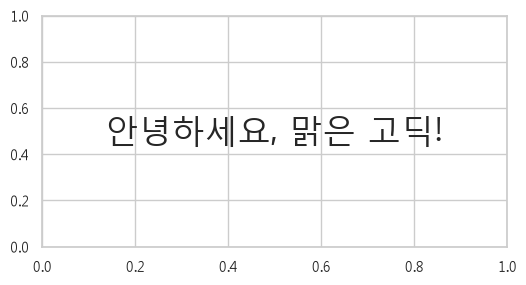

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# seaborn 스타일을 먼저 적용
sns.set_theme(style="whitegrid")

# Windows 한글 글꼴 설정
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# 한글 표시 확인
plt.figure(figsize=(6, 3))
plt.text(
    0.5, 0.5,
    "안녕하세요, 맑은 고딕!",
    ha="center",
    va="center",
    size=24
)
plt.show()

## MySQL 연결

In [14]:
import pandas as pd
from getpass import getpass
from sqlalchemy import create_engine, URL, text

url = URL.create(
    drivername="mysql+pymysql",
    username="root",
    password=getpass("MySQL 비밀번호: "),
    host="localhost",
    port=3306,
    database="final",
    query={"charset": "utf8mb4"},
)

engine = create_engine(url, pool_pre_ping=True)

# 연결 확인
with engine.connect() as conn:
    print(conn.execute(text("SELECT VERSION()")).scalar())

8.0.37


In [15]:
query = "SELECT * FROM accounts_user LIMIT 5"

with engine.connect() as conn:
    df = pd.read_sql_query(text(query), conn)

df.head()

,id,is_superuser,is_staff,gender,point,friend_id_list,is_push_on,created_at,block_user_id_list,hide_user_id_list,ban_status,report_count,alarm_count,pending_chat,pending_votes,group_id
0,831956,1,1,None,600,"[1292473, 913158, 1488461, 1064695, 1043565, 1...",0,2023-03-29 03:44:14.047130,[],[],N,0,0,0,0,NaN
1,831962,0,0,F,2248,"[833025, 832642, 982531, 879496, 838541, 83752...",1,2023-03-29 05:18:56.162368,[],[],N,253,40878,5499,110,12.0
2,832151,0,0,M,1519,"[838785, 982531, 882567, 879496, 838541, 83649...",0,2023-03-29 12:56:34.989468,[],[],N,0,37,0,47,1.0
3,832340,0,0,F,57,"[841345, 982531, 838785, 963714, 882567, 83252...",1,2023-03-29 12:56:35.020790,[],[],N,0,19,0,21,1.0
4,832520,0,0,M,1039,"[874050, 849763, 874212, 844297, 838541, 84004...",0,2023-03-29 12:56:35.049311,[],[],N,0,29,0,15,12.0


## DataFrame에 저장

In [16]:
import pandas as pd
from sqlalchemy import text

params = {
    "start_at": "2023-05-04 00:00:00",
    "end_at": "2024-05-06 00:00:00",
}

queries = {
    "polls_question": """
        SELECT
            id,
            TRIM(question_text) AS question_text,
            created_at
        FROM final.polls_question
    """,

    "polls_questionreport": """
        SELECT
            id,
            TRIM(reason) AS reason,
            created_at,
            question_id,
            user_id
        FROM final.polls_questionreport
        WHERE created_at >= :start_at
          AND created_at < :end_at
    """,

    "polls_usercandidate": """
        SELECT
            id,
            created_at,
            question_piece_id,
            user_id
        FROM final.polls_usercandidate
        WHERE created_at >= :start_at
          AND created_at < :end_at
    """,

    "polls_questionset": """
        SELECT
            id,
            question_piece_id_list,
            opening_time,
            status,
            user_id
        FROM final.polls_questionset
        WHERE opening_time >= created_at
          AND status = 'F'
          AND created_at >= :start_at
          AND created_at < :end_at
    """,

    "polls_questionpiece": """
        SELECT
            id,
            is_voted,
            question_id,
            is_skipped
        FROM final.polls_questionpiece
        WHERE created_at >= :start_at
          AND created_at < :end_at
    """,

    "accounts_userquestionrecord": """
        SELECT
            id,
            status,
            created_at,
            chosen_user_id,
            question_id,
            user_id,
            question_piece_id,
            has_read,
            answer_status,
            answer_updated_at,
            report_count,
            opened_times
        FROM final.accounts_userquestionrecord
        WHERE answer_status <> 'P'
          AND created_at >= :start_at
          AND created_at < :end_at
    """,

    # 가입일 제한 없이 일반 유저 전체 조회
    "accounts_user": """
        SELECT
            id,
            is_superuser,
            is_staff,
            gender,
            friend_id_list,
            is_push_on,
            created_at,
            block_user_id_list,
            hide_user_id_list,
            ban_status,
            report_count,
            group_id
        FROM final.accounts_user
        WHERE is_superuser = 0
          AND is_staff = 0
    """,

    "accounts_timelinereport": """
        SELECT
            id,
            TRIM(reason) AS reason,
            created_at,
            reported_user_id,
            user_id,
            user_question_record_id
        FROM final.accounts_timelinereport
        WHERE created_at >= :start_at
          AND created_at < :end_at
    """,

    "accounts_school": """
        SELECT
            id,
            student_count,
            school_type
        FROM final.accounts_school
    """,

    "accounts_group": """
        SELECT
            id,
            school_id
        FROM final.accounts_group
    """,

    "accounts_blockrecord": """
        SELECT
            id,
            TRIM(reason) AS reason,
            created_at,
            block_user_id,
            user_id
        FROM final.accounts_blockrecord
        WHERE created_at >= :start_at
          AND created_at < :end_at
    """,

    # 생성일 컬럼이 없어 전체 조회
    "accounts_attendance": """
        SELECT
            id,
            attendance_date_list,
            user_id
        FROM final.accounts_attendance
    """,
}

dfs = {}

with engine.connect() as conn:
    for table_name, query in queries.items():
        dfs[table_name] = pd.read_sql_query(
            text(query),
            conn,
            params=params,
        )

        df = dfs[table_name]
        print(f"{table_name}: {len(df):,}행 × {len(df.columns)}열")

# 개별 DataFrame 변수
df_question = dfs["polls_question"]
df_questionreport = dfs["polls_questionreport"]
df_usercandidate = dfs["polls_usercandidate"]
df_questionset = dfs["polls_questionset"]
df_questionpiece = dfs["polls_questionpiece"]
df_userquestionrecord = dfs["accounts_userquestionrecord"]
df_user = dfs["accounts_user"]
df_timelinereport = dfs["accounts_timelinereport"]
df_school = dfs["accounts_school"]
df_group = dfs["accounts_group"]
df_blockrecord = dfs["accounts_blockrecord"]
df_attendance = dfs["accounts_attendance"]

polls_question: 5,025행 × 3열
polls_questionreport: 48,928행 × 5열
polls_usercandidate: 4,452,529행 × 4열
polls_questionset: 141,909행 × 5열
polls_questionpiece: 1,177,414행 × 4열
accounts_userquestionrecord: 1,128,249행 × 12열
accounts_user: 677,081행 × 12열
accounts_timelinereport: 208행 × 6열
accounts_school: 5,951행 × 3열
accounts_group: 84,515행 × 2열
accounts_blockrecord: 19,481행 × 5열
accounts_attendance: 349,637행 × 3열


In [17]:
query_attendance = """
SELECT
    id,
    attendance_date_list,
    user_id
FROM final.accounts_attendance
"""

with engine.connect() as conn:
    df_attendance = pd.read_sql_query(text(query_attendance), conn)

dfs["accounts_attendance"] = df_attendance

print(f"accounts_attendance: {len(df_attendance):,}행 × {len(df_attendance.columns)}열")

df_attendance.head()

accounts_attendance: 349,637행 × 3열


,id,attendance_date_list,user_id
0,1,"[""2023-05-27"", ""2023-05-28"", ""2023-05-29"", ""20...",1446852
1,2,"[""2023-05-27"", ""2023-05-29"", ""2023-05-30"", ""20...",1359398
2,3,"[""2023-05-27"", ""2023-05-29"", ""2023-05-30"", ""20...",1501542
3,4,"[""2023-05-27"", ""2023-05-28"", ""2023-05-29"", ""20...",1507767
4,5,"[""2023-05-27"", ""2023-05-28"", ""2023-05-29"", ""20...",1287453


# 전처리

## 중복값 확인

In [18]:
duplicate_results = []

for table_name, df in dfs.items():
    duplicate_results.append({
        "테이블": table_name,
        "전체 행 수": len(df),

        # 첫 행을 제외한 추가 중복 행 수
        "전체 컬럼 중복 행 수": int(df.duplicated().sum()),

        # 기본키 중복 및 누락
        "ID 중복 수": (
            int(df["id"].duplicated().sum())
            if "id" in df.columns else pd.NA
        ),
        "ID 결측 수": (
            int(df["id"].isna().sum())
            if "id" in df.columns else pd.NA
        ),
    })

df_duplicate_summary = pd.DataFrame(duplicate_results)

df_duplicate_summary

,테이블,전체 행 수,전체 컬럼 중복 행 수,ID 중복 수,ID 결측 수
0,polls_question,5025,0,0,0
1,polls_questionreport,48928,0,0,0
2,polls_usercandidate,4452529,0,0,0
3,polls_questionset,141909,0,0,0
4,polls_questionpiece,1177414,0,0,0
5,accounts_userquestionrecord,1128249,0,0,0
6,accounts_user,677081,0,0,0
7,accounts_timelinereport,208,0,0,0
8,accounts_school,5951,0,0,0
9,accounts_group,84515,0,0,0


## 질문 합치기 & 불필요한 질문 드랍

In [19]:
import pandas as pd

# 문서에 정리된 중복 질문 묶음 (같은 튜플 = 같은 질문)
DUPLICATE_GROUPS = [
    # 2. 띄어쓰기·문장부호·단순 오타만 다른 묶음
    (779, 3967, 4950), (3297, 4280), (2753, 2754), (1627, 2486), (3330, 4313),
    (2439, 2440), (2399, 2400), (1250, 2338), (1431, 2283), (1407, 2163),
    (1470, 1978), (729, 1966, 3777, 4760), (673, 1883), (3429, 4412), (3987, 4970),

    # 3-1. 어미·조사가 다른 묶음
    (765, 3133), (1042, 2001), (121, 3454, 4437), (741, 1585, 3084, 3085), (891, 3074),
    (1361, 1624), (1085, 3032), (683, 3014), (1031, 3009), (624, 3003),
    (2996, 2997), (982, 2990), (128, 589), (1345, 3256, 4239), (2908, 2909),
    (1529, 2904), (582, 2777), (2691, 3760, 4743), (1336, 2680), (1375, 2668),
    (1284, 2624), (1246, 2615), (1442, 2518, 4039, 5022), (2504, 3632, 4615), (174, 1198),
    (118, 1329), (381, 2404), (1373, 2307), (1509, 2291), (629, 4127, 5110),
    (2237, 2240), (2214, 4133, 5116), (2169, 2170), (611, 2161), (358, 2155),
    (1169, 2081), (2053, 3448, 4431), (502, 3486, 4469), (1001, 1973),
    (1951, 3547, 4530, 3961, 4944), (1948, 1949), (1548, 1946), (1429, 1929, 1930),
    (1900, 1902), (1061, 1894), (1410, 1879), (748, 1848), (613, 1776),
    (896, 1759), (577, 1738), (1456, 1686), (114, 1150), (345, 1165),
    (1301, 3025), (1382, 2317),

    # 3-2. 유의어·어순·어조가 다른 묶음
    (1013, 1221), (298, 1239, 2202, 3979, 4962), (1634, 2099, 3940, 4923), (1630, 1994),
    (246, 3169, 4152), (597, 2540), (119, 2361, 2362), (228, 2327, 3092), (1224, 2125),
    (672, 1808), (1265, 1727, 3375, 4358), (201, 1356), (1347, 3037), (1168, 3283, 4266),
    (322, 2917), (797, 4136, 5119), (1332, 2784), (1207, 2759), (510, 2733, 3134),
    (1552, 2008), (3127, 3209, 4192), (216, 2693), (313, 501), (453, 3123),
    (1148, 2631), (548, 994), (115, 2490), (1220, 2481), (866, 1030),
    (635, 2448), (2441, 3105), (1491, 3100), (2384, 3099), (301, 986),
    (2036, 3228, 4211), (1319, 3533, 4516), (1888, 3176, 4159), (622, 1853),
    (142, 3980, 4963), (492, 2667), (122, 2492), (599, 3741, 4724), (316, 1271),
    (2228, 2229), (180, 1618),

    # 4-3. 일반 구간 내 텍스트 완전 일치
    (782, 3163), (287, 1391, 3160), (1558, 3159), (1632, 3043), (521, 1492),
    (1598, 3103), (1508, 3096), (3084, 3085), (1299, 3073), (197, 763),
    (1309, 3062), (608, 3059), (1029, 3226, 4209), (1359, 3007), (182, 1124),
    (823, 2968), (674, 2967), (1421, 2964), (2958, 2959), (634, 2954),
    (1395, 2948), (831, 2940), (1503, 2924), (1537, 2915), (1599, 2912),
    (1437, 2883), (1641, 2879), (2868, 2869), (1581, 2847), (1628, 2835),
    (1469, 2812), (856, 2809), (2801, 2802), (1533, 2800), (2775, 2776),
    (708, 2761), (838, 1397, 2750), (2720, 2721), (1565, 2702), (553, 1489),
    (746, 2688), (1571, 2634), (1596, 2599), (1244, 2595), (1617, 2590),
    (1383, 2537), (1639, 2530), (1442, 2518), (870, 2503), (2449, 2450),
    (2445, 2446), (2428, 2429), (1273, 2427), (1341, 2396), (1638, 2373),
    (1637, 2314), (1331, 2309), (868, 2259), (684, 2226), (2220, 2221),
    (1453, 2203), (1342, 2188), (1616, 2181), (1337, 2175), (1549, 2173),
    (1190, 2157), (2127, 2128), (1028, 2112), (2098, 3511, 4494), (1403, 2096),
    (2090, 2091), (730, 2087), (1411, 2083), (1499, 2062), (2051, 2052),
    (1440, 2044), (1623, 2032), (2006, 2007), (1436, 1971), (729, 1966),
    (1951, 3547, 4530), (1315, 1933), (1929, 1930), (1640, 1855), (836, 1839),
    (1279, 1830), (790, 1821), (1772, 1773), (1614, 1769), (1398, 1750),
    (1416, 1742), (1446, 1740), (750, 1728), (1349, 1717), (835, 1687),
    (1237, 1629), (1669, 1670), (620, 1664),
]

# 4-2. 분석에서 제거할 ID ("vote", "포인트")
REMOVE_IDS = {
    186, 483, 639, 696, 712, 725, 736, 807, 881, 940, 946, 1139, 1219, 1232, 1320,
    1507, 1591, 1651, 1652, 1653, 1654, 1655, 1656, 1657, 1658, 1747, 1749, 2129,
    2246, 2565, 2843, 2916, 3200, 3216, 3314, 3353, 3367, 3447, 3564, 3566, 3695,
    3913, 3915, 4033, 4183, 4199, 4297, 4336, 4350, 4430, 4547, 4549, 4678, 4896,
    4898, 5016,
    3956, 4939,
}

# 4-1. 블록 복제 구간: ID 4151~5133 = ID 3168~4150 (+983)
BLOCK_START, BLOCK_END, BLOCK_OFFSET = 3168, 4150, 983


class QuestionIdMapper:
    """중복 질문 ID를 묶음 내 가장 작은 ID로 치환한다.

    - 블록 복제 구간(4151~5133)은 원본 ID(-983)와 같은 묶음으로 본다.
    - 묶음이 서로 이어지면(예: 4950 → 3967 → 779) 하나로 합쳐 가장 작은 ID로 보낸다.
    - "vote", "포인트" ID는 NA로 바꾼다.
    """

    def __init__(self):
        parent = {}

        def find(x):
            parent.setdefault(x, x)
            while parent[x] != x:
                parent[x] = parent[parent[x]]
                x = parent[x]
            return x

        def union(a, b):
            ra, rb = find(a), find(b)
            if ra != rb:
                # 루트를 항상 작은 ID로 유지 → 루트가 곧 대표 ID
                parent[max(ra, rb)] = min(ra, rb)

        for group in DUPLICATE_GROUPS:
            for qid in group[1:]:
                union(group[0], qid)
        for qid in range(BLOCK_START, BLOCK_END + 1):
            union(qid, qid + BLOCK_OFFSET)

        self.mapping = {qid: find(qid) for qid in parent if find(qid) != qid}
        self.remove_ids = set(REMOVE_IDS)

    def map_id(self, qid):
        """ID 하나를 대표 ID로 바꾼다. 제거 대상이면 None."""
        if qid in self.remove_ids:
            return None
        return self.mapping.get(qid, qid)

    def transform(self, ids):
        """ID 리스트/Series를 대표 ID Series(Int64)로 바꾼다. 제거 대상은 NA."""
        s = ids if isinstance(ids, pd.Series) else pd.Series(ids)
        return s.map(self.map_id).astype("Int64")


In [20]:
mapper = QuestionIdMapper()

# 원본 question_id는 유지
df_questionreport_clean = df_questionreport.copy()

df_questionreport_clean["대표 질문 ID"] = mapper.transform(
    df_questionreport_clean["question_id"]
)

# REMOVE_IDS에 해당하는 행 제외
df_questionreport_clean = df_questionreport_clean.dropna(
    subset=["대표 질문 ID"]
)

In [21]:
mapper = QuestionIdMapper()

print(
    "전체 질문 통합 후 질문 수:",
    f"{mapper.transform(df_question['id']).nunique():,}개",
)

전체 질문 통합 후 질문 수: 3,778개


In [22]:
# clean 신고 데이터에 포함된 고유 대표 질문 수
print(
    "질문을 합쳤을 때 신고가 된 질문 수:",
    f"{df_questionreport_clean['대표 질문 ID'].nunique():,}개",
)

질문을 합쳤을 때 신고가 된 질문 수: 2,902개


In [23]:
print(
    "총 질문 수:",
    f"{df_questionreport['question_id'].nunique():,}개",
)

총 질문 수: 3,135개


### 전처리한 질문 CSV 파일로 내보내기

In [47]:
from pathlib import Path

save_path = Path.cwd() / "대표질문_통합목록.csv"

if save_path.exists():
    print(f"파일이 이미 있어 실행을 건너뜁니다: {save_path.resolve()}")

else:
    mapper = QuestionIdMapper()

    df_question_export = df_question[
        ["id", "question_text"]
    ].copy()

    df_question_export["대표 질문 ID"] = mapper.transform(
        df_question_export["id"]
    )

    # 제외 대상 질문 제거
    df_question_export = df_question_export.dropna(
        subset=["대표 질문 ID"]
    )

    # 같은 묶음에 포함된 원본 ID 보관
    df_question_export = (
        df_question_export
        .groupby("대표 질문 ID")
        .agg(
            원본_질문_ID=("id", lambda s: ", ".join(
                map(str, sorted(s))
            )),
            통합_질문_수=("id", "size"),
        )
        .reset_index()
        .merge(
            df_question[["id", "question_text"]].rename(columns={
                "id": "대표 질문 ID",
                "question_text": "대표 질문명",
            }),
            on="대표 질문 ID",
            how="left",
            validate="one_to_one",
        )
        .rename(columns={
            "원본_질문_ID": "원본 질문 ID 목록",
            "통합_질문_수": "통합된 원본 질문 수",
        })
        .sort_values("대표 질문 ID")
        .reset_index(drop=True)
    )

    df_question_export["대표 질문 ID"] = (
        df_question_export["대표 질문 ID"].astype("int64")
    )

    df_question_export = df_question_export[[
        "대표 질문 ID",
        "대표 질문명",
        "원본 질문 ID 목록",
        "통합된 원본 질문 수",
    ]]

    df_question_export.to_csv(
        save_path,
        index=False,
        encoding="utf-8-sig",
        mode="x",
    )

    print(f"통합 후 질문 수: {len(df_question_export):,}개")
    print(f"저장 위치: {save_path.resolve()}")

    display(df_question_export.head(10))

파일이 이미 있어 실행을 건너뜁니다: C:\Users\USER\Desktop\final_prj\codeit-sns-moderation\대표질문_통합목록.csv


# EDA

## 전체 질문 신고 순위 확인

### 질문 신고 순위

In [25]:
# 긍정적 사유 제외
positive_mask = (
    df_questionreport_clean["reason"]
    .astype("string")
    .str.strip()
    .eq("어떻게 이런 생각을? 이 질문 최고!")
    .fillna(False)
)

df_question_report_top10 = (
    df_questionreport_clean.loc[
        ~positive_mask
        & df_questionreport_clean["대표 질문 ID"].notna()
    ]
    .groupby("대표 질문 ID")
    .agg(
        신고_수=("id", "size"),
        고유_신고자_수=("user_id", "nunique"),
    )
    .reset_index()
    .merge(
        df_question[["id", "question_text"]].rename(columns={
            "id": "대표 질문 ID",
            "question_text": "질문명",
        }),
        on="대표 질문 ID",
        how="left",
        validate="one_to_one",
    )
    .rename(columns={
        "신고_수": "신고 수",
        "고유_신고자_수": "고유 신고자 수",
    })
    [["대표 질문 ID", "질문명", "신고 수", "고유 신고자 수"]]
    .sort_values(
        ["신고 수", "고유 신고자 수", "대표 질문 ID"],
        ascending=[False, False, True],
    )
    .head(10)
    .reset_index(drop=True)
)

df_question_report_top10

,대표 질문 ID,질문명,신고 수,고유 신고자 수
0,111,마스크가 잘 어울리는 사람은?,891,693
1,410,발냄새가 호두과자 냄새일 것 같은 사람은?,791,678
2,398,등빨이 가장 좋은 사람은?,657,554
3,424,어깨가 가장 넓은 사람은?,531,458
4,305,먹방을 가장 잘할 것 같은 사람은?,475,392
5,564,설레면 콧구멍이 커지는 친구는?,338,309
6,144,발냄새가 가장 향긋할 것 같은 사람은?,284,246
7,519,콧수염을 기르면 잘 어울릴 것 같은 사람은?,281,243
8,494,먹방 찍으면 100만 유튜버가 될 것 같은 친구,256,209
9,479,치킨 중독인 것 같은 사람은?,235,196


### 질문 신고 사유 순위

In [26]:
# clean 기준 — 긍정 사유 포함
reasons = (
    df_questionreport_clean["reason"]
    .astype("string")
    .str.strip()
    .fillna("사유 미기재")
    .replace("", "사유 미기재")
)

df_question_report_reason_ranking = (
    reasons.value_counts()
    .rename_axis("신고 사유")
    .reset_index(name="신고 수")
)

total_reports = df_question_report_reason_ranking["신고 수"].sum()

df_question_report_reason_ranking["비율(%)"] = (
    df_question_report_reason_ranking["신고 수"]
    / total_reports * 100
    if total_reports else float("nan")
)

df_question_report_reason_ranking.round(2)

,신고 사유,신고 수,비율(%)
0,그냥 싫어,28178,58.16
1,나랑 맞지 않는 질문인 것 같음,9435,19.47
2,불쾌한 질문 내용,5351,11.04
3,자꾸 같은 내용의 질문 반복,3157,6.52
4,한 친구가 질문을 반복적으로 보냄,1685,3.48
5,어떻게 이런 생각을? 이 질문 최고!,381,0.79
6,이 질문은 재미없어요,92,0.19
7,기타,83,0.17
8,불쾌한 내용이 포함되어 있음,72,0.15
9,오타가 있음,10,0.02


## 학생들의 신고·차단 행동 패턴

### 성별에 따른 질문 신고 Top10

In [27]:
# 포함할 신고 사유
target_reasons = [
    "그냥 싫어",
    "나랑 맞지 않는 질문인 것 같음",
    "불쾌한 질문 내용",
    "이 질문은 재미없어요",
    "기타",
    "불쾌한 내용이 포함되어 있음",
    "선정적이거나 자극적인 질문",
]

# 대표 질문 ID가 적용된 clean 데이터 사용
df_gender_reports = (
    df_questionreport_clean.loc[
        df_questionreport_clean["reason"]
        .astype("string")
        .str.strip()
        .isin(target_reasons)
    ]
    .dropna(subset=["대표 질문 ID"])
    .merge(
        df_user[["id", "gender"]].rename(columns={"id": "user_id"}),
        on="user_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        df_question[["id", "question_text"]].rename(columns={
            "id": "대표 질문 ID",
            "question_text": "질문명",
        }),
        on="대표 질문 ID",
        how="left",
        validate="many_to_one",
    )
)


def get_gender_top10(gender, label):
    return (
        df_gender_reports.loc[
            df_gender_reports["gender"].eq(gender)
        ]
        .groupby(["대표 질문 ID", "질문명"], dropna=False)
        .size()
        .reset_index(name=f"{label} 신고 수")
        .sort_values(
            [f"{label} 신고 수", "대표 질문 ID"],
            ascending=[False, True],
        )
        .head(10)
        .rename(columns={
            "대표 질문 ID": f"{label} 대표 질문 ID",
            "질문명": f"{label} 질문명",
        })
        .reset_index(drop=True)
    )


df_gender_question_top10 = pd.concat(
    [
        get_gender_top10("F", "여학생"),
        get_gender_top10("M", "남학생"),
    ],
    axis=1,
)

print(
    "성별 확인 불가 신고:",
    f"{df_gender_reports['gender'].isna().sum():,}건",
)

df_gender_question_top10

성별 확인 불가 신고: 0건


,여학생 대표 질문 ID,여학생 질문명,여학생 신고 수,남학생 대표 질문 ID,남학생 질문명,남학생 신고 수
0,111,마스크가 잘 어울리는 사람은?,639,410,발냄새가 호두과자 냄새일 것 같은 사람은?,290
1,398,등빨이 가장 좋은 사람은?,611,111,마스크가 잘 어울리는 사람은?,206
2,424,어깨가 가장 넓은 사람은?,477,564,설레면 콧구멍이 커지는 친구는?,89
3,410,발냄새가 호두과자 냄새일 것 같은 사람은?,468,144,발냄새가 가장 향긋할 것 같은 사람은?,85
4,305,먹방을 가장 잘할 것 같은 사람은?,369,465,어부가 될 가능성이 가장 높은 사람은?,81
5,564,설레면 콧구멍이 커지는 친구는?,238,460,농부가 될 가능성이 가장 높은 사람은?,80
6,519,콧수염을 기르면 잘 어울릴 것 같은 사람은?,203,305,먹방을 가장 잘할 것 같은 사람은?,76
7,494,먹방 찍으면 100만 유튜버가 될 것 같은 친구,188,516,매일 공유킥보드 타고 다니는 친구는?,74
8,144,발냄새가 가장 향긋할 것 같은 사람은?,182,476,거의 움직이지 않는 친구는?,73
9,479,치킨 중독인 것 같은 사람은?,182,477,항상 냄새를 맡으려고 하는 친구는?,68


### 학급에 따른 질문 신고 Top10

In [28]:
target_reasons = [
    "그냥 싫어",
    "나랑 맞지 않는 질문인 것 같음",
    "불쾌한 질문 내용",
    "이 질문은 재미없어요",
    "기타",
    "불쾌한 내용이 포함되어 있음",
    "선정적이거나 자극적인 질문",
]

df_school_reports_check = (
    df_questionreport_clean.loc[
        df_questionreport_clean["reason"]
        .astype("string")
        .str.strip()
        .isin(target_reasons)
    ]
    .dropna(subset=["대표 질문 ID"])
    .merge(
        df_user[["id", "gender", "group_id"]].rename(
            columns={"id": "user_id"}
        ),
        on="user_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        df_group[["id", "school_id"]].rename(
            columns={"id": "group_id"}
        ),
        on="group_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        df_school[["id", "school_type"]].rename(
            columns={"id": "school_id"}
        ),
        on="school_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        df_question[["id", "question_text"]].rename(columns={
            "id": "대표 질문 ID",
            "question_text": "질문명",
        }),
        on="대표 질문 ID",
        how="left",
        validate="many_to_one",
    )
    .dropna(subset=["school_type"])
)


def get_school_top10(school_type, label):
    return (
        df_school_reports_check.loc[
            df_school_reports_check["school_type"].eq(school_type)
        ]
        .groupby(["대표 질문 ID", "질문명"], dropna=False)
        .size()
        .reset_index(name=f"{label} 신고 수")
        .sort_values(
            [f"{label} 신고 수", "대표 질문 ID"],
            ascending=[False, True],
        )
        .head(10)
        .rename(columns={
            "대표 질문 ID": f"{label} 대표 질문 ID",
            "질문명": f"{label} 질문명",
        })
        .reset_index(drop=True)
    )


df_school_question_top10 = pd.concat(
    [
        get_school_top10("M", "중학교"),
        get_school_top10("H", "고등학교"),
    ],
    axis=1,
)

df_school_question_top10

,중학교 대표 질문 ID,중학교 질문명,중학교 신고 수,고등학교 대표 질문 ID,고등학교 질문명,고등학교 신고 수
0,410,발냄새가 호두과자 냄새일 것 같은 사람은?,407,111,마스크가 잘 어울리는 사람은?,448
1,111,마스크가 잘 어울리는 사람은?,397,410,발냄새가 호두과자 냄새일 것 같은 사람은?,351
2,398,등빨이 가장 좋은 사람은?,319,398,등빨이 가장 좋은 사람은?,313
3,424,어깨가 가장 넓은 사람은?,265,424,어깨가 가장 넓은 사람은?,244
4,305,먹방을 가장 잘할 것 같은 사람은?,248,305,먹방을 가장 잘할 것 같은 사람은?,197
5,564,설레면 콧구멍이 커지는 친구는?,180,564,설레면 콧구멍이 커지는 친구는?,147
6,519,콧수염을 기르면 잘 어울릴 것 같은 사람은?,150,144,발냄새가 가장 향긋할 것 같은 사람은?,131
7,494,먹방 찍으면 100만 유튜버가 될 것 같은 친구,138,519,콧수염을 기르면 잘 어울릴 것 같은 사람은?,119
8,144,발냄새가 가장 향긋할 것 같은 사람은?,136,138,첫 키스를 가장 먼저 해봤을 것 같은 사람은?,110
9,479,치킨 중독인 것 같은 사람은?,132,494,먹방 찍으면 100만 유튜버가 될 것 같은 친구,104


### 질문 신고자의 차단·숨김 실행 현황

In [29]:
import json
import pandas as pd

user_base = df_user.loc[
    df_user["is_superuser"].eq(0)
    & df_user["is_staff"].eq(0)
].copy()

if user_base["id"].isna().any() or user_base["id"].duplicated().any():
    raise ValueError("유저 ID의 결측·중복을 확인해 주세요.")


def has_hidden_users(value):
    if isinstance(value, str):
        value = json.loads(value)
    elif isinstance(value, list):
        pass
    elif pd.isna(value):
        return pd.NA
    else:
        raise ValueError("숨김 목록 형식을 확인해 주세요.")

    if value is None:
        return pd.NA

    if not isinstance(value, list):
        raise ValueError("숨김 목록이 리스트 형식이 아닙니다.")

    return len(value) > 0


# 차단한 사람: 차단 기록의 user_id
blocker_ids = set(df_blockrecord["user_id"].dropna())

df_user_action_flags = user_base[["id"]].copy()

df_user_action_flags["차단 실행"] = (
    df_user_action_flags["id"].isin(blocker_ids)
)

# 숨김한 사람: 본인의 숨김 목록에 대상이 한 명 이상 있음
df_user_action_flags["숨김 실행"] = (
    user_base["hide_user_id_list"]
    .apply(has_hidden_users)
    .astype("boolean")
)

total_users = len(df_user_action_flags)

df_user_action_ratio = pd.DataFrame([
    {
        "구분": label,
        "고유 유저 수": int(
            df_user_action_flags[column].fillna(False).sum()
        ),
        "전체 일반 유저 수": total_users,
        "전체 대비 비율(%)": (
            df_user_action_flags[column].fillna(False).sum()
            / total_users * 100
            if total_users else float("nan")
        ),
    }
    for label, column in [
        ("차단한 유저", "차단 실행"),
        ("숨김한 유저", "숨김 실행"),
    ]
])

print(
    "숨김 목록 확인 불가:",
    f"{df_user_action_flags['숨김 실행'].isna().sum():,}명",
)

df_user_action_ratio.round(2)

숨김 목록 확인 불가: 0명


,구분,고유 유저 수,전체 일반 유저 수,전체 대비 비율(%)
0,차단한 유저,12551,677081,1.85
1,숨김한 유저,78733,677081,11.63


In [30]:
# 긍정적 사유를 제외한 고유 질문 신고자
positive_mask = (
    df_questionreport_clean["reason"]
    .astype("string")
    .str.strip()
    .eq("어떻게 이런 생각을? 이 질문 최고!")
    .fillna(False)
)

df_reporter_actions = (
    df_questionreport_clean.loc[~positive_mask, ["user_id"]]
    .dropna(subset=["user_id"])
    .drop_duplicates()
    .merge(
        df_user_action_flags.rename(columns={"id": "user_id"}),
        on="user_id",
        how="left",
        validate="one_to_one",
        indicator=True,
    )
)

# 일반 유저 정보에 연결되지 않는 신고자를 자동 제외하지 않음
unmatched = df_reporter_actions["_merge"].ne("both")

if unmatched.any():
    raise ValueError(
        f"일반 유저 정보에 연결되지 않는 신고자가 "
        f"{unmatched.sum():,}명 있습니다. 분석 대상 범위를 확인해 주세요."
    )

block = df_reporter_actions["차단 실행"].astype("boolean")
hide = df_reporter_actions["숨김 실행"].astype("boolean")

total_reporters = len(df_reporter_actions)

conditions = [
    ("차단한 질문 신고자", block),
    ("숨김한 질문 신고자", hide),
    ("차단·숨김 모두 한 질문 신고자", block & hide),
    ("차단 또는 숨김한 질문 신고자", block | hide),
]

df_reporter_action_ratio = pd.DataFrame([
    {
        "구분": label,
        "고유 유저 수": int(mask.fillna(False).sum()),
        "전체 질문 신고자 수": total_reporters,
        "확인 불가 유저 수": int(mask.isna().sum()),
        "질문 신고자 대비 비율(%)": (
            mask.fillna(False).sum() / total_reporters * 100
            if total_reporters else float("nan")
        ),
    }
    for label, mask in conditions
])

df_reporter_action_ratio.round(2)

,구분,고유 유저 수,전체 질문 신고자 수,확인 불가 유저 수,질문 신고자 대비 비율(%)
0,차단한 질문 신고자,1087,20544,0,5.29
1,숨김한 질문 신고자,4529,20544,0,22.05
2,차단·숨김 모두 한 질문 신고자,488,20544,0,2.38
3,차단 또는 숨김한 질문 신고자,5128,20544,0,24.96


### 성별, 학급별 유저 신고, 차단 & 숨김 활용 시 다르게 보이는지 패턴 확인

#### 성별

In [48]:
import json
import pandas as pd

# 전체 일반 유저
df_action_users = df_user.loc[
    df_user["is_superuser"].eq(0)
    & df_user["is_staff"].eq(0),
    ["id", "gender", "hide_user_id_list"],
].copy()

if (
    df_action_users["id"].isna().any()
    or df_action_users["id"].duplicated().any()
):
    raise ValueError("유저 ID의 결측·중복을 확인해 주세요.")


def has_hide_target(value):
    if isinstance(value, str):
        value = json.loads(value)

    if isinstance(value, list):
        return len(value) > 0

    if value is None or pd.isna(value):
        return pd.NA

    raise ValueError("숨김 목록 형식을 확인해 주세요.")


df_action_users["성별"] = (
    df_action_users["gender"]
    .map({"F": "여학생", "M": "남학생"})
    .fillna("확인 불가")
)

# 기능별 실행 여부
df_action_users["유저 신고"] = df_action_users["id"].isin(
    df_timelinereport["user_id"].dropna().unique()
)

df_action_users["차단"] = df_action_users["id"].isin(
    df_blockrecord["user_id"].dropna().unique()
)

df_action_users["숨김"] = (
    df_action_users["hide_user_id_list"]
    .apply(has_hide_target)
    .astype("boolean")
)


def gender_ratio_table(feature):
    users = df_action_users.loc[
        df_action_users[feature].fillna(False)
    ]

    result = (
        users["성별"]
        .value_counts()
        .reindex(["여학생", "남학생", "확인 불가"], fill_value=0)
        .rename_axis("성별")
        .reset_index(name="고유 실행자 수")
    )

    result["성별 비율(%)"] = (
        result["고유 실행자 수"] / len(users) * 100
        if len(users) else float("nan")
    )

    return result.round(2)


df_reporter_gender_ratio = gender_ratio_table("유저 신고")
df_blocker_gender_ratio = gender_ratio_table("차단")
df_hider_gender_ratio = gender_ratio_table("숨김")

print("유저 신고 실행자의 성별 비율")
display(df_reporter_gender_ratio)

print("차단 실행자의 성별 비율")
display(df_blocker_gender_ratio)

print("숨김 실행자의 성별 비율")
display(df_hider_gender_ratio)

유저 신고 실행자의 성별 비율


,성별,고유 실행자 수,성별 비율(%)
0,여학생,28,24.35
1,남학생,87,75.65
2,확인 불가,0,0.00


차단 실행자의 성별 비율


,성별,고유 실행자 수,성별 비율(%)
0,여학생,7650,60.95
1,남학생,4901,39.05
2,확인 불가,0,0.00


숨김 실행자의 성별 비율


,성별,고유 실행자 수,성별 비율(%)
0,여학생,44801,56.9
1,남학생,33932,43.1
2,확인 불가,0,0.0


In [49]:
target_reasons = [
    "그냥 싫어",
    "나랑 맞지 않는 질문인 것 같음",
    "불쾌한 질문 내용",
    "이 질문은 재미없어요",
    "기타",
    "불쾌한 내용이 포함되어 있음",
    "선정적이거나 자극적인 질문",
]

# 지정 사유 7개에 해당하는 고유 질문 신고자
target_mask = (
    df_questionreport_clean["reason"]
    .astype("string")
    .str.strip()
    .isin(target_reasons)
)

question_reporter_ids = (
    df_questionreport_clean.loc[target_mask, "user_id"]
    .dropna()
    .unique()
)

df_action_users["질문 신고"] = (
    df_action_users["id"].isin(question_reporter_ids)
)

df_question_reporter_gender_ratio = gender_ratio_table("질문 신고")

print("질문 신고 실행자의 성별 비율")
display(df_question_reporter_gender_ratio)

질문 신고 실행자의 성별 비율


,성별,고유 실행자 수,성별 비율(%)
0,여학생,12118,63.74
1,남학생,6895,36.26
2,확인 불가,0,0.00


#### 학급

In [50]:
import json
import pandas as pd

# 일반 유저 → 학급 → 학교급 연결
df_school_action_users = (
    df_user.loc[
        df_user["is_superuser"].eq(0)
        & df_user["is_staff"].eq(0),
        ["id", "group_id", "hide_user_id_list"],
    ]
    .rename(columns={"id": "user_id"})
    .merge(
        df_group[["id", "school_id"]].rename(
            columns={"id": "group_id"}
        ),
        on="group_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        df_school[["id", "school_type"]].rename(
            columns={"id": "school_id"}
        ),
        on="school_id",
        how="left",
        validate="many_to_one",
    )
)

if (
    df_school_action_users["user_id"].isna().any()
    or df_school_action_users["user_id"].duplicated().any()
):
    raise ValueError("유저 ID의 결측·중복을 확인해 주세요.")


def has_hide_target(value):
    if isinstance(value, str):
        value = json.loads(value)

    if isinstance(value, list):
        return len(value) > 0

    if value is None or pd.isna(value):
        return pd.NA

    raise ValueError("숨김 목록 형식을 확인해 주세요.")


df_school_action_users["학교급"] = (
    df_school_action_users["school_type"]
    .map({"M": "중학교", "H": "고등학교"})
    .fillna("확인 불가")
)

# 실행자 기준
df_school_action_users["유저 신고"] = (
    df_school_action_users["user_id"].isin(
        df_timelinereport["user_id"].dropna().unique()
    )
)

df_school_action_users["차단"] = (
    df_school_action_users["user_id"].isin(
        df_blockrecord["user_id"].dropna().unique()
    )
)

df_school_action_users["숨김"] = (
    df_school_action_users["hide_user_id_list"]
    .apply(has_hide_target)
    .astype("boolean")
)


def school_type_ratio_table(feature):
    users = df_school_action_users.loc[
        df_school_action_users[feature].fillna(False)
    ]

    result = (
        users["학교급"]
        .value_counts()
        .reindex(["중학교", "고등학교", "확인 불가"], fill_value=0)
        .rename_axis("학교급")
        .reset_index(name="고유 실행자 수")
    )

    result["학교급 비율(%)"] = (
        result["고유 실행자 수"] / len(users) * 100
        if len(users) else float("nan")
    )

    return result.round(2)


df_reporter_school_ratio = school_type_ratio_table("유저 신고")
df_blocker_school_ratio = school_type_ratio_table("차단")
df_hider_school_ratio = school_type_ratio_table("숨김")

print("유저 신고 실행자의 학교급 비율")
display(df_reporter_school_ratio)

print("차단 실행자의 학교급 비율")
display(df_blocker_school_ratio)

print("숨김 실행자의 학교급 비율")
display(df_hider_school_ratio)

유저 신고 실행자의 학교급 비율


,학교급,고유 실행자 수,학교급 비율(%)
0,중학교,19,16.52
1,고등학교,96,83.48
2,확인 불가,0,0.00


차단 실행자의 학교급 비율


,학교급,고유 실행자 수,학교급 비율(%)
0,중학교,5473,43.61
1,고등학교,7077,56.39
2,확인 불가,1,0.01


숨김 실행자의 학교급 비율


,학교급,고유 실행자 수,학교급 비율(%)
0,중학교,35026,44.49
1,고등학교,43706,55.51
2,확인 불가,1,0.00


In [51]:
target_reasons = [
    "그냥 싫어",
    "나랑 맞지 않는 질문인 것 같음",
    "불쾌한 질문 내용",
    "이 질문은 재미없어요",
    "기타",
    "불쾌한 내용이 포함되어 있음",
    "선정적이거나 자극적인 질문",
]

# 지정 사유 7개에 해당하는 고유 질문 신고자
target_mask = (
    df_questionreport_clean["reason"]
    .astype("string")
    .str.strip()
    .isin(target_reasons)
)

question_reporter_ids = (
    df_questionreport_clean.loc[target_mask, "user_id"]
    .dropna()
    .unique()
)

df_school_action_users["질문 신고"] = (
    df_school_action_users["user_id"].isin(question_reporter_ids)
)

df_question_reporter_school_ratio = (
    school_type_ratio_table("질문 신고")
)

print("질문 신고 실행자의 학교급 비율")
display(df_question_reporter_school_ratio)

질문 신고 실행자의 학교급 비율


,학교급,고유 실행자 수,학교급 비율(%)
0,중학교,8839,46.49
1,고등학교,10173,53.51
2,확인 불가,1,0.01


#### 패턴 확인

##### 투표 실행 횟수

In [52]:
import json
import pandas as pd

df_action_vote_users = df_user.loc[
    df_user["is_superuser"].eq(0)
    & df_user["is_staff"].eq(0),
    ["id", "hide_user_id_list"],
].copy()

if (
    df_action_vote_users["id"].isna().any()
    or df_action_vote_users["id"].duplicated().any()
):
    raise ValueError("유저 ID의 결측·중복을 확인해 주세요.")


def has_hide_target(value):
    if isinstance(value, str):
        value = json.loads(value)

    if isinstance(value, list):
        return len(value) > 0

    if value is None or pd.isna(value):
        return pd.NA

    raise ValueError("숨김 목록 형식을 확인해 주세요.")


blocker_ids = set(df_blockrecord["user_id"].dropna())

df_action_vote_users["차단 실행"] = (
    df_action_vote_users["id"].isin(blocker_ids)
)
df_action_vote_users["숨김 실행"] = (
    df_action_vote_users["hide_user_id_list"]
    .apply(has_hide_target)
    .astype("boolean")
)

df_action_vote_users["그룹"] = "확인 불가"

known_hide = df_action_vote_users["숨김 실행"].notna()
block = df_action_vote_users["차단 실행"]
hide = df_action_vote_users["숨김 실행"].fillna(False)

df_action_vote_users.loc[
    known_hide & ~block & ~hide, "그룹"
] = "둘 다 없음"

df_action_vote_users.loc[
    known_hide & block & ~hide, "그룹"
] = "차단만 실행"

df_action_vote_users.loc[
    known_hide & ~block & hide, "그룹"
] = "숨김만 실행"

df_action_vote_users.loc[
    known_hide & block & hide, "그룹"
] = "차단·숨김 모두 실행"

In [53]:
# user_id: 투표를 실행한 사용자
vote_counts = (
    df_userquestionrecord
    .groupby("user_id")
    .size()
    .rename("투표 실행 횟수")
)

df_action_vote_users = (
    df_action_vote_users
    .drop(
        columns=[
            "투표 실행 횟수",
            "후보 선택 횟수",
            "질문 수신량",
        ],
        errors="ignore",
    )
    .merge(
        vote_counts,
        left_on="id",
        right_index=True,
        how="left",
        validate="one_to_one",
    )
)

df_action_vote_users["투표 실행 횟수"] = (
    df_action_vote_users["투표 실행 횟수"]
    .fillna(0)
    .astype("int64")
)

group_order = [
    "차단만 실행",
    "숨김만 실행",
    "차단·숨김 모두 실행",
    "둘 다 없음",
    "확인 불가",
]

df_action_vote_summary = (
    df_action_vote_users
    .groupby("그룹")
    .agg(
        유저_수=("id", "size"),
        투표_기록_있는_유저_수=(
            "투표 실행 횟수", lambda s: s.gt(0).sum()
        ),
        평균_투표_실행_횟수=("투표 실행 횟수", "mean"),
        최대_투표_실행_횟수=("투표 실행 횟수", "max"),
        관측된_투표_기록_없는_비율=(
            "투표 실행 횟수", lambda s: s.eq(0).mean() * 100
        ),
    )
    .reindex(group_order)
    .dropna(subset=["유저_수"])
    .reset_index()
    .rename(columns={
        "유저_수": "유저 수",
        "투표_기록_있는_유저_수": "관측된 투표 기록 있는 유저 수",
        "평균_투표_실행_횟수": "평균 투표 실행 횟수",
        "최대_투표_실행_횟수": "최대 투표 실행 횟수",
        "관측된_투표_기록_없는_비율": "관측된 투표 기록 없는 비율(%)",
    })
)

df_action_vote_summary.round(2)

,그룹,유저 수,관측된 투표 기록 있는 유저 수,평균 투표 실행 횟수,최대 투표 실행 횟수,관측된 투표 기록 없는 비율(%)
0,차단만 실행,7927.0,60.0,2.89,1171.0,99.24
1,숨김만 실행,74109.0,578.0,2.42,1679.0,99.22
2,차단·숨김 모두 실행,4624.0,36.0,2.72,901.0,99.22
3,둘 다 없음,590421.0,4139.0,1.55,2034.0,99.30


##### 투표 받은 횟수

In [54]:
# chosen_user_id: 투표에서 선택받은 유저
received_counts = (
    df_userquestionrecord
    .groupby("chosen_user_id")
    .size()
    .rename("투표 받은 횟수")
)

df_action_vote_users = (
    df_action_vote_users
    .drop(columns=["투표 받은 횟수"], errors="ignore")
    .merge(
        received_counts,
        left_on="id",
        right_index=True,
        how="left",
        validate="one_to_one",
    )
)

df_action_vote_users["투표 받은 횟수"] = (
    df_action_vote_users["투표 받은 횟수"]
    .fillna(0)
    .astype("int64")
)

group_order = [
    "차단만 실행",
    "숨김만 실행",
    "차단·숨김 모두 실행",
    "둘 다 없음",
    "확인 불가",
]

df_action_received_summary = (
    df_action_vote_users
    .groupby("그룹")
    .agg(
        유저_수=("id", "size"),
        수신_기록_있는_유저_수=(
            "투표 받은 횟수", lambda s: s.gt(0).sum()
        ),
        평균_투표_받은_횟수=("투표 받은 횟수", "mean"),
        최대_투표_받은_횟수=("투표 받은 횟수", "max"),
        수신_기록_없는_비율=(
            "투표 받은 횟수", lambda s: s.eq(0).mean() * 100
        ),
    )
    .reindex(group_order)
    .dropna(subset=["유저_수"])
    .reset_index()
    .rename(columns={
        "유저_수": "유저 수",
        "수신_기록_있는_유저_수": "투표 받은 기록 있는 유저 수",
        "평균_투표_받은_횟수": "평균 투표 받은 횟수",
        "최대_투표_받은_횟수": "최대 투표 받은 횟수",
        "수신_기록_없는_비율": "투표 받은 기록 없는 비율(%)",
    })
)

df_action_received_summary.round(2)

,그룹,유저 수,투표 받은 기록 있는 유저 수,평균 투표 받은 횟수,최대 투표 받은 횟수,투표 받은 기록 없는 비율(%)
0,차단만 실행,7927.0,182.0,2.27,572.0,97.70
1,숨김만 실행,74109.0,1873.0,2.05,948.0,97.47
2,차단·숨김 모두 실행,4624.0,104.0,2.37,1053.0,97.75
3,둘 다 없음,590421.0,13084.0,1.60,1239.0,97.78


##### 출석일 수

In [55]:
import json
import pandas as pd

attendance_start = pd.Timestamp("2023-05-04")
attendance_end = pd.Timestamp("2024-05-06")  # 미포함


def parse_attendance_dates(value):
    if isinstance(value, str):
        value = json.loads(value)

    if isinstance(value, list):
        return value

    if value is None or pd.isna(value):
        return []

    raise ValueError("출석 날짜 목록 형식을 확인해 주세요.")


# 출석 목록 펼치기
df_attendance_dates = (
    df_attendance[["user_id", "attendance_date_list"]]
    .assign(
        출석일=lambda df: df["attendance_date_list"].apply(
            parse_attendance_dates
        )
    )
    .explode("출석일")
    .dropna(subset=["출석일"])
    [["user_id", "출석일"]]
)

# 잘못된 날짜가 있으면 오류로 확인
df_attendance_dates["출석일"] = pd.to_datetime(
    df_attendance_dates["출석일"],
    errors="raise",
).dt.normalize()

# 분석 기간 적용 + 같은 유저의 같은 날짜 중복 제거
df_attendance_dates = (
    df_attendance_dates.loc[
        df_attendance_dates["출석일"].ge(attendance_start)
        & df_attendance_dates["출석일"].lt(attendance_end)
    ]
    .drop_duplicates(["user_id", "출석일"])
)

attendance_counts = (
    df_attendance_dates
    .groupby("user_id")
    .size()
    .rename("출석일 수")
)

# 기존 차단·숨김 실행자 그룹에 연결
df_action_vote_users = (
    df_action_vote_users
    .drop(columns=["출석일 수"], errors="ignore")
    .merge(
        attendance_counts,
        left_on="id",
        right_index=True,
        how="left",
        validate="one_to_one",
    )
)

df_action_vote_users["출석일 수"] = (
    df_action_vote_users["출석일 수"]
    .fillna(0)
    .astype("int64")
)

group_order = [
    "차단만 실행",
    "숨김만 실행",
    "차단·숨김 모두 실행",
    "둘 다 없음",
    "확인 불가",
]

df_action_attendance_summary = (
    df_action_vote_users
    .groupby("그룹")
    .agg(
        유저_수=("id", "size"),
        출석_기록_있는_유저_수=(
            "출석일 수", lambda s: s.gt(0).sum()
        ),
        평균_출석일_수=("출석일 수", "mean"),
        최대_출석일_수=("출석일 수", "max"),
        출석_기록_없는_비율=(
            "출석일 수", lambda s: s.eq(0).mean() * 100
        ),
    )
    .reindex(group_order)
    .dropna(subset=["유저_수"])
    .reset_index()
    .rename(columns={
        "유저_수": "유저 수",
        "출석_기록_있는_유저_수": "출석 기록 있는 유저 수",
        "평균_출석일_수": "평균 출석일 수",
        "최대_출석일_수": "최대 출석일 수",
        "출석_기록_없는_비율": "출석 기록 없는 비율(%)",
    })
)

df_action_attendance_summary.round(2)

,그룹,유저 수,출석 기록 있는 유저 수,평균 출석일 수,최대 출석일 수,출석 기록 없는 비율(%)
0,차단만 실행,7927.0,5253.0,5.23,213.0,33.73
1,숨김만 실행,74109.0,46679.0,5.06,274.0,37.01
2,차단·숨김 모두 실행,4624.0,3426.0,6.87,181.0,25.91
3,둘 다 없음,590421.0,273323.0,3.00,306.0,53.71


##### 친구 수

In [56]:
import json
import pandas as pd


def count_unique_friends(value):
    if isinstance(value, str):
        value = json.loads(value)

    if isinstance(value, list):
        return len({int(user_id) for user_id in value})

    if value is None or pd.isna(value):
        return pd.NA

    raise ValueError("친구 목록 형식을 확인해 주세요.")


df_friend_counts = df_user[["id", "friend_id_list"]].copy()

df_friend_counts["친구 수"] = (
    df_friend_counts["friend_id_list"]
    .apply(count_unique_friends)
    .astype("Int64")
)

# 기존 실행자 그룹에 연결
df_action_vote_users = (
    df_action_vote_users
    .drop(columns=["친구 수"], errors="ignore")
    .merge(
        df_friend_counts[["id", "친구 수"]],
        on="id",
        how="left",
        validate="one_to_one",
    )
)

group_order = [
    "차단만 실행",
    "숨김만 실행",
    "차단·숨김 모두 실행",
    "둘 다 없음",
    "확인 불가",
]

df_action_friend_summary = (
    df_action_vote_users
    .groupby("그룹")
    .agg(
        유저_수=("id", "size"),
        친구_수_확인_가능=("친구 수", "count"),
        평균_친구_수=("친구 수", "mean"),
        최대_친구_수=("친구 수", "max"),
        친구_0명_유저_수=(
            "친구 수", lambda s: s.eq(0).sum()
        ),
    )
    .reindex(group_order)
    .dropna(subset=["유저_수"])
    .reset_index()
)

df_action_friend_summary["친구 0명 비율(%)"] = (
    df_action_friend_summary["친구_0명_유저_수"]
    .div(
        df_action_friend_summary["친구_수_확인_가능"].where(
            df_action_friend_summary["친구_수_확인_가능"] > 0
        )
    )
    .mul(100)
)

df_action_friend_summary = df_action_friend_summary.rename(columns={
    "유저_수": "유저 수",
    "친구_수_확인_가능": "친구 수 확인 가능 유저 수",
    "평균_친구_수": "평균 친구 수",
    "최대_친구_수": "최대 친구 수",
    "친구_0명_유저_수": "친구 0명 유저 수",
})

df_action_friend_summary.round(2)

,그룹,유저 수,친구 수 확인 가능 유저 수,평균 친구 수,최대 친구 수,친구 0명 유저 수,친구 0명 비율(%)
0,차단만 실행,7927.0,7927,60.66,438,2,0.03
1,숨김만 실행,74109.0,74109,67.5,1373,34,0.05
2,차단·숨김 모두 실행,4624.0,4624,67.27,778,3,0.06
3,둘 다 없음,590421.0,590421,51.34,1222,2832,0.48


## 후속조치 확인

### 분포도 확인

#### 투표기록 수 분포도

,전체 질문 묶음 기준
count,3778.00
mean,296.18
std,464.02
min,3.00
25%,19.00
50%,31.00
75%,366.00
90%,1312.20
95%,1468.30
99%,1585.23


,투표 기록 수 구간,질문 묶음 수,비율(%)
0,0건,0,0.00
1,1~10건,243,6.43
2,11~50건,2018,53.41
3,51~100건,21,0.56
4,101~300건,101,2.67
5,301~500건,842,22.29
6,"501~1,000건",95,2.51
7,"1,001건 이상",458,12.12


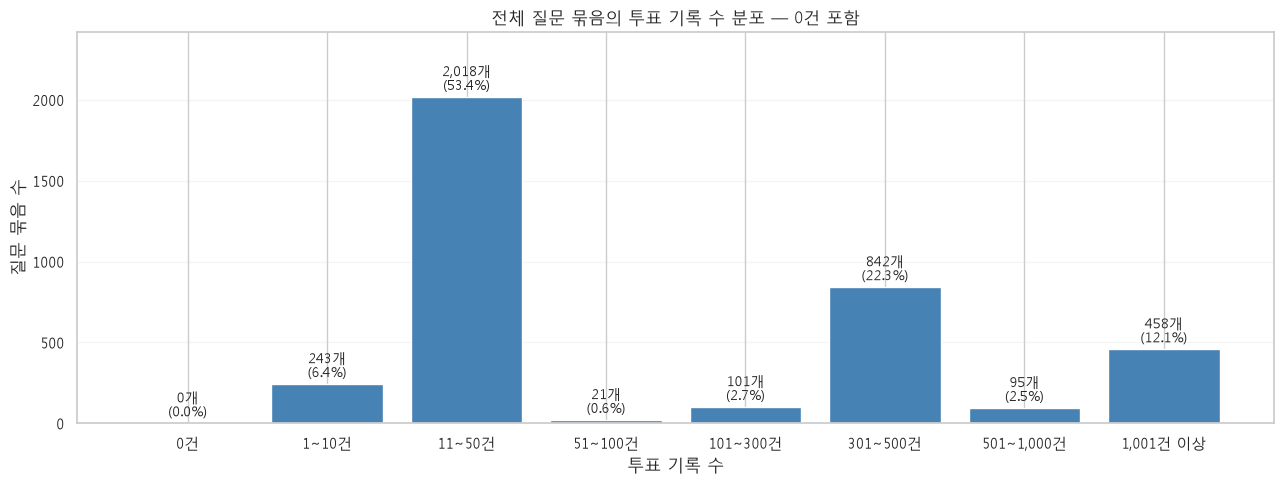

In [40]:
import pandas as pd
import matplotlib.pyplot as plt

mapper = QuestionIdMapper()

# 1. 전체 대표 질문 목록
df_all_question_votes = (
    mapper.transform(df_question["id"])
    .dropna()
    .drop_duplicates()
    .rename("대표 질문 ID")
    .to_frame()
    .reset_index(drop=True)
)

# 2. 전체 투표 기록에 대표 ID 적용
df_vote_records = df_userquestionrecord[
    ["id", "question_id"]
].copy()

df_vote_records["대표 질문 ID"] = mapper.transform(
    df_vote_records["question_id"]
)

vote_counts = (
    df_vote_records
    .dropna(subset=["대표 질문 ID"])
    .groupby("대표 질문 ID")["id"]
    .nunique()
    .rename("투표 기록 수")
    .reset_index()
)

# 3. 투표 기록이 없는 질문은 0건
df_all_question_votes = df_all_question_votes.merge(
    vote_counts,
    on="대표 질문 ID",
    how="left",
    validate="one_to_one",
)

df_all_question_votes["투표 기록 수"] = (
    df_all_question_votes["투표 기록 수"]
    .fillna(0)
    .astype("int64")
)

# 기초 통계
display(
    df_all_question_votes["투표 기록 수"]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99])
    .to_frame("전체 질문 묶음 기준")
    .round(2)
)

# 4. 구간별 분포
bins = [-1, 0, 10, 50, 100, 300, 500, 1000, float("inf")]
labels = [
    "0건", "1~10건", "11~50건", "51~100건",
    "101~300건", "301~500건", "501~1,000건", "1,001건 이상",
]

df_vote_distribution = (
    pd.cut(
        df_all_question_votes["투표 기록 수"],
        bins=bins,
        labels=labels,
    )
    .value_counts(sort=False)
    .rename_axis("투표 기록 수 구간")
    .reset_index(name="질문 묶음 수")
)

total_questions = len(df_all_question_votes)

df_vote_distribution["비율(%)"] = (
    df_vote_distribution["질문 묶음 수"] / total_questions * 100
    if total_questions else float("nan")
).round(2)

display(df_vote_distribution)

# 5. 분포 그래프
fig, ax = plt.subplots(figsize=(13, 5))

bars = ax.bar(
    df_vote_distribution["투표 기록 수 구간"],
    df_vote_distribution["질문 묶음 수"],
    color="steelblue",
)

for bar, count, ratio in zip(
    bars,
    df_vote_distribution["질문 묶음 수"],
    df_vote_distribution["비율(%)"],
):
    ax.annotate(
        f"{count:,}개\n({ratio:.1f}%)",
        xy=(bar.get_x() + bar.get_width() / 2, count),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontsize=10,
    )

ax.set_title("전체 질문 묶음의 투표 기록 수 분포 — 0건 포함")
ax.set_xlabel("투표 기록 수")
ax.set_ylabel("질문 묶음 수")
ax.margins(y=0.2)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

#### 신고에 대한 분포도

,전체 질문 묶음 기준
count,3778.00
mean,11.44
std,31.92
min,0.00
25%,0.00
50%,2.00
75%,13.00
90%,29.00
95%,43.00
99%,110.38


,신고 건수 구간,질문 묶음 수,비율(%)
0,0건,979,25.91
1,1건,768,20.33
2,2~5건,586,15.51
3,6~10건,310,8.21
4,11~20건,521,13.79
5,21~50건,477,12.63
6,51~100건,92,2.44
7,101건 이상,45,1.19


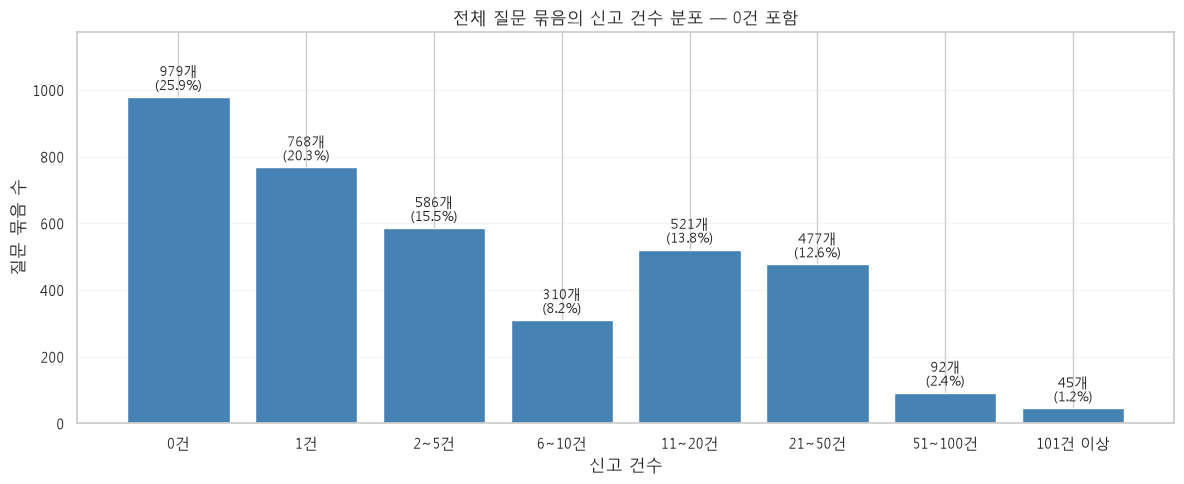

In [41]:
import pandas as pd
import matplotlib.pyplot as plt

mapper = QuestionIdMapper()

target_reasons = [
    "그냥 싫어",
    "나랑 맞지 않는 질문인 것 같음",
    "불쾌한 질문 내용",
    "이 질문은 재미없어요",
    "기타",
    "불쾌한 내용이 포함되어 있음",
    "선정적이거나 자극적인 질문",
]

# 1. 전체 질문을 대표 ID로 통합
all_question_ids = (
    mapper.transform(df_question["id"])
    .dropna()
    .drop_duplicates()
)

df_all_question_reports = (
    all_question_ids
    .rename("대표 질문 ID")
    .to_frame()
    .reset_index(drop=True)
)

# 2. 지정 사유의 질문별 신고 수
report_counts = (
    df_questionreport_clean.loc[
        df_questionreport_clean["reason"]
        .astype("string")
        .str.strip()
        .isin(target_reasons)
    ]
    .groupby("대표 질문 ID")
    .size()
    .rename("신고 수")
    .reset_index()
)

# 3. 신고가 없는 질문은 0건
df_all_question_reports = df_all_question_reports.merge(
    report_counts,
    on="대표 질문 ID",
    how="left",
    validate="one_to_one",
)

df_all_question_reports["신고 수"] = (
    df_all_question_reports["신고 수"].fillna(0).astype("int64")
)

# 기초 통계
display(
    df_all_question_reports["신고 수"]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99])
    .to_frame("전체 질문 묶음 기준")
    .round(2)
)

# 4. 구간별 분포
bins = [-1, 0, 1, 5, 10, 20, 50, 100, float("inf")]
labels = [
    "0건", "1건", "2~5건", "6~10건",
    "11~20건", "21~50건", "51~100건", "101건 이상",
]

df_report_distribution = (
    pd.cut(
        df_all_question_reports["신고 수"],
        bins=bins,
        labels=labels,
    )
    .value_counts(sort=False)
    .rename_axis("신고 건수 구간")
    .reset_index(name="질문 묶음 수")
)

df_report_distribution["비율(%)"] = (
    df_report_distribution["질문 묶음 수"]
    / len(df_all_question_reports) * 100
    if len(df_all_question_reports) else float("nan")
).round(2)

display(df_report_distribution)

# 5. 분포 그래프
fig, ax = plt.subplots(figsize=(12, 5))

bars = ax.bar(
    df_report_distribution["신고 건수 구간"],
    df_report_distribution["질문 묶음 수"],
    color="steelblue",
)

for bar, count, ratio in zip(
    bars,
    df_report_distribution["질문 묶음 수"],
    df_report_distribution["비율(%)"],
):
    ax.annotate(
        f"{count:,}개\n({ratio:.1f}%)",
        xy=(bar.get_x() + bar.get_width() / 2, count),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontsize=10,
    )

ax.set_title("전체 질문 묶음의 신고 건수 분포 — 0건 포함")
ax.set_xlabel("신고 건수")
ax.set_ylabel("질문 묶음 수")
ax.margins(y=0.2)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

#### 읽음 처리된 투표 기록 수 분포

,전체 질문 묶음 기준
count,3778.00
mean,171.12
std,272.27
min,0.00
25%,7.00
50%,14.00
75%,212.00
90%,771.30
95%,849.00
99%,937.46


,읽음 기록 수 구간,질문 묶음 수,비율(%)
0,0건,10,0.26
1,1~10건,1406,37.22
2,11~50건,866,22.92
3,51~100건,0,0.00
4,101~300건,943,24.96
5,301~500건,51,1.35
6,"501~1,000건",488,12.92
7,"1,001건 이상",14,0.37


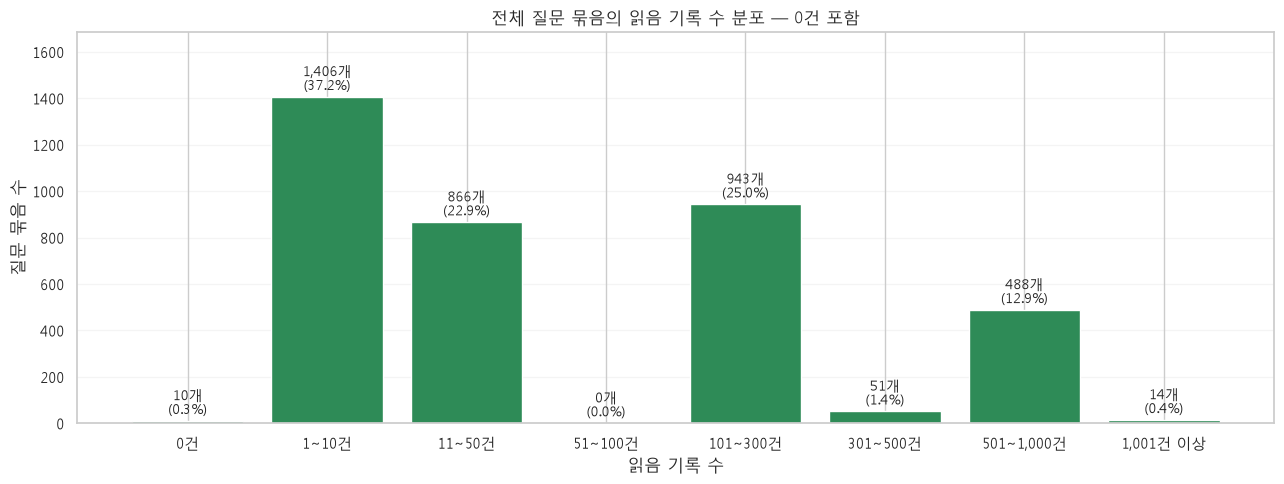

In [42]:
import pandas as pd
import matplotlib.pyplot as plt

mapper = QuestionIdMapper()

# 1. 전체 대표 질문 목록
df_all_question_reads = (
    mapper.transform(df_question["id"])
    .dropna()
    .drop_duplicates()
    .rename("대표 질문 ID")
    .to_frame()
    .reset_index(drop=True)
)

# 2. 읽음 처리된 투표 기록에 대표 ID 적용
df_read_records = df_userquestionrecord.loc[
    df_userquestionrecord["has_read"].eq(1),
    ["id", "question_id"],
].copy()

df_read_records["대표 질문 ID"] = mapper.transform(
    df_read_records["question_id"]
)

read_counts = (
    df_read_records
    .dropna(subset=["대표 질문 ID"])
    .groupby("대표 질문 ID")["id"]
    .nunique()
    .rename("읽음 기록 수")
    .reset_index()
)

# 3. 읽음 기록이 없는 질문은 0건
df_all_question_reads = df_all_question_reads.merge(
    read_counts,
    on="대표 질문 ID",
    how="left",
    validate="one_to_one",
)

df_all_question_reads["읽음 기록 수"] = (
    df_all_question_reads["읽음 기록 수"]
    .fillna(0)
    .astype("int64")
)

# 기초 통계
display(
    df_all_question_reads["읽음 기록 수"]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99])
    .to_frame("전체 질문 묶음 기준")
    .round(2)
)

# 4. 구간별 분포
bins = [-1, 0, 10, 50, 100, 300, 500, 1000, float("inf")]
labels = [
    "0건", "1~10건", "11~50건", "51~100건",
    "101~300건", "301~500건", "501~1,000건", "1,001건 이상",
]

df_read_distribution = (
    pd.cut(
        df_all_question_reads["읽음 기록 수"],
        bins=bins,
        labels=labels,
    )
    .value_counts(sort=False)
    .rename_axis("읽음 기록 수 구간")
    .reset_index(name="질문 묶음 수")
)

total_questions = len(df_all_question_reads)

df_read_distribution["비율(%)"] = (
    df_read_distribution["질문 묶음 수"] / total_questions * 100
    if total_questions else float("nan")
).round(2)

display(df_read_distribution)

# 5. 분포 그래프
fig, ax = plt.subplots(figsize=(13, 5))

bars = ax.bar(
    df_read_distribution["읽음 기록 수 구간"],
    df_read_distribution["질문 묶음 수"],
    color="seagreen",
)

for bar, count, ratio in zip(
    bars,
    df_read_distribution["질문 묶음 수"],
    df_read_distribution["비율(%)"],
):
    ax.annotate(
        f"{count:,}개\n({ratio:.1f}%)",
        xy=(bar.get_x() + bar.get_width() / 2, count),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontsize=10,
    )

ax.set_title("전체 질문 묶음의 읽음 기록 수 분포 — 0건 포함")
ax.set_xlabel("읽음 기록 수")
ax.set_ylabel("질문 묶음 수")
ax.margins(y=0.2)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

## 신고가 많은 질문의 투표 추이와 질문 종류 증가에 따른 비중 변화 분석

### 신고가 많은 질문 16개의 최다 신고일 전후 투표 건수·비중 변화

In [43]:
import pandas as pd

mapper = QuestionIdMapper()

# 대표 질문 ID 16개
question_ids = [
    111, 138, 144, 305, 398, 410, 424, 460,
    465, 476, 477, 479, 494, 516, 519, 564,
]

n_questions = len(question_ids)

target_reasons = [
    "그냥 싫어",
    "나랑 맞지 않는 질문인 것 같음",
    "불쾌한 질문 내용",
    "이 질문은 재미없어요",
    "기타",
    "불쾌한 내용이 포함되어 있음",
    "선정적이거나 자극적인 질문",
]

# 1. 선정한 대표 질문의 날짜별 합산 신고 수
reports = df_questionreport_clean.loc[
    df_questionreport_clean["대표 질문 ID"].isin(question_ids)
    & df_questionreport_clean["reason"]
        .astype("string")
        .str.strip()
        .isin(target_reasons)
].copy()

reports["날짜"] = pd.to_datetime(
    reports["created_at"]
).dt.normalize()

# 현재 DF의 조회 기간
data_start = pd.Timestamp(params["start_at"]).normalize()
data_end = (
    pd.Timestamp(params["end_at"]) - pd.Timedelta(nanoseconds=1)
).normalize()

reports = reports.loc[
    reports["날짜"].between(data_start, data_end)
].copy()

daily_reports = reports.groupby("날짜").size()

if daily_reports.empty:
    raise ValueError("선정한 질문과 신고 사유에 해당하는 기록이 없습니다.")

# 최다 신고일이 여러 날이면 가장 이른 날
reference_date = daily_reports.sort_index().idxmax()

# 2. 전체 투표 기록에 대표 질문 ID 적용
votes = df_userquestionrecord[
    ["id", "question_id", "created_at"]
].copy()

votes["대표 질문 ID"] = mapper.transform(
    votes["question_id"]
)

votes["날짜"] = pd.to_datetime(
    votes["created_at"]
).dt.normalize()

# 조회 기간 적용 + mapper 제외 대상 제거
votes = votes.loc[
    votes["날짜"].between(data_start, data_end)
    & votes["대표 질문 ID"].notna()
].copy()

# 집계 표: 조회 가능한 범위에서 최다 신고일 전후 30일
start_date = max(
    reference_date - pd.Timedelta(days=30),
    data_start,
)
end_date = min(
    reference_date + pd.Timedelta(days=30),
    data_end,
)

dates = pd.date_range(start_date, end_date, freq="D")

# 3. 날짜 × 대표 질문 조합 생성
# 같은 묶음의 원본 질문 투표를 합산하고, 기록이 없으면 0건
daily_question_votes = (
    votes.loc[votes["대표 질문 ID"].isin(question_ids)]
    .groupby(["날짜", "대표 질문 ID"])["id"]
    .nunique()
    .reindex(
        pd.MultiIndex.from_product(
            [dates, question_ids],
            names=["날짜", "대표 질문 ID"],
        ),
        fill_value=0,
    )
    .rename("질문 투표 수")
    .reset_index()
)

# 분모: mapper 제외 대상을 제거한 전체 질문의 투표 기록
# 선정한 16개 질문으로 제한하지 않음
daily_total_votes = (
    votes.groupby("날짜")["id"]
    .nunique()
    .rename("전체 투표 수")
)

daily_question_votes = daily_question_votes.merge(
    daily_total_votes,
    left_on="날짜",
    right_index=True,
    how="left",
    validate="many_to_one",
)

daily_question_votes["전체 투표 수"] = (
    daily_question_votes["전체 투표 수"]
    .fillna(0)
    .astype("int64")
)

# 질문별 일별 투표 비중
# 전체 투표가 0건인 날은 비중을 결측으로 유지
denominator = daily_question_votes["전체 투표 수"]

daily_question_votes["질문 투표 비중(%)"] = (
    daily_question_votes["질문 투표 수"]
    .div(denominator.where(denominator.gt(0)))
    .mul(100)
)

# 4. 매일 동일한 16개 질문의 평균 계산
vote_sum_col = f"{n_questions}개 질문 합산 투표 수"
report_sum_col = f"{n_questions}개 질문 합산 신고 수"

df_daily_question_average = (
    daily_question_votes
    .groupby("날짜")
    .agg(
        질문당_평균_투표_수=("질문 투표 수", "mean"),
        질문당_평균_투표_비중=(
            "질문 투표 비중(%)", "mean"
        ),
        선정_질문_합산_투표_수=("질문 투표 수", "sum"),
        전체_투표_수=("전체 투표 수", "first"),
    )
    .rename(columns={
        "질문당_평균_투표_수": "질문당 평균 투표 수",
        "질문당_평균_투표_비중": "질문당 평균 투표 비중(%)",
        "선정_질문_합산_투표_수": vote_sum_col,
        "전체_투표_수": "전체 투표 수",
    })
)

df_daily_question_average[report_sum_col] = (
    daily_reports.reindex(dates, fill_value=0)
)

df_daily_question_average = (
    df_daily_question_average.reset_index()
)

df_daily_question_average["기준일 대비 일수"] = (
    df_daily_question_average["날짜"] - reference_date
).dt.days

df_daily_question_average = df_daily_question_average[[
    "날짜",
    "기준일 대비 일수",
    report_sum_col,
    "질문당 평균 투표 수",
    "질문당 평균 투표 비중(%)",
    vote_sum_col,
    "전체 투표 수",
]]

print(
    f"공통 기준일: {reference_date:%Y-%m-%d}"
    f" / 합산 신고 {daily_reports.loc[reference_date]:,}건"
)
print(
    f"관측 범위: {start_date:%Y-%m-%d}"
    f" ~ {end_date:%Y-%m-%d}"
)
print(f"평균의 분모: 매일 동일한 대표 질문 {n_questions}개")
print("전체 투표 수: mapper 제외 대상을 제거한 기록 기준")
print(
    f"관측 가능한 기간: 기준일 이전 "
    f"{(reference_date - start_date).days}일"
    f" / 이후 {(end_date - reference_date).days}일"
)

display(
    df_daily_question_average.round({
        "질문당 평균 투표 수": 2,
        "질문당 평균 투표 비중(%)": 4,
    })
)

C:\Users\USER\AppData\Local\Temp\ipykernel_39600\3253915363.py:39: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  pd.Timestamp(params["end_at"]) - pd.Timedelta(nanoseconds=1)
C:\Users\USER\AppData\Local\Temp\ipykernel_39600\3253915363.py:75: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  reference_date - pd.Timedelta(days=30),
C:\Users\USER\AppData\Local\Temp\ipykernel_39600\3253915363.py:79: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  reference_date + pd.Timedelta(days=30),


공통 기준일: 2023-05-14 / 합산 신고 561건
관측 범위: 2023-05-04 ~ 2023-06-13
평균의 분모: 매일 동일한 대표 질문 16개
전체 투표 수: mapper 제외 대상을 제거한 기록 기준
관측 가능한 기간: 기준일 이전 10일 / 이후 30일


,날짜,기준일 대비 일수,16개 질문 합산 신고 수,질문당 평균 투표 수,질문당 평균 투표 비중(%),16개 질문 합산 투표 수,전체 투표 수
0,2023-05-04,-10,18,39.25,0.1730,628,22692
1,2023-05-05,-9,32,77.25,0.1877,1236,41154
2,2023-05-06,-8,153,93.00,0.1940,1488,47940
3,2023-05-07,-7,279,85.62,0.1942,1370,44081
4,2023-05-08,-6,302,67.25,0.1992,1076,33767
5,2023-05-09,-5,313,55.50,0.1909,888,29078
6,2023-05-10,-4,377,61.88,0.2018,990,30658
7,2023-05-11,-3,381,67.75,0.1906,1084,35540
8,2023-05-12,-2,356,80.25,0.1723,1284,46571
9,2023-05-13,-1,539,109.06,0.1694,1745,64365


C:\Users\USER\AppData\Local\Temp\ipykernel_39600\86435909.py:6: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  graph_start = reference_date - pd.Timedelta(days=10)
C:\Users\USER\AppData\Local\Temp\ipykernel_39600\86435909.py:7: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  graph_end = reference_date + pd.Timedelta(days=10)


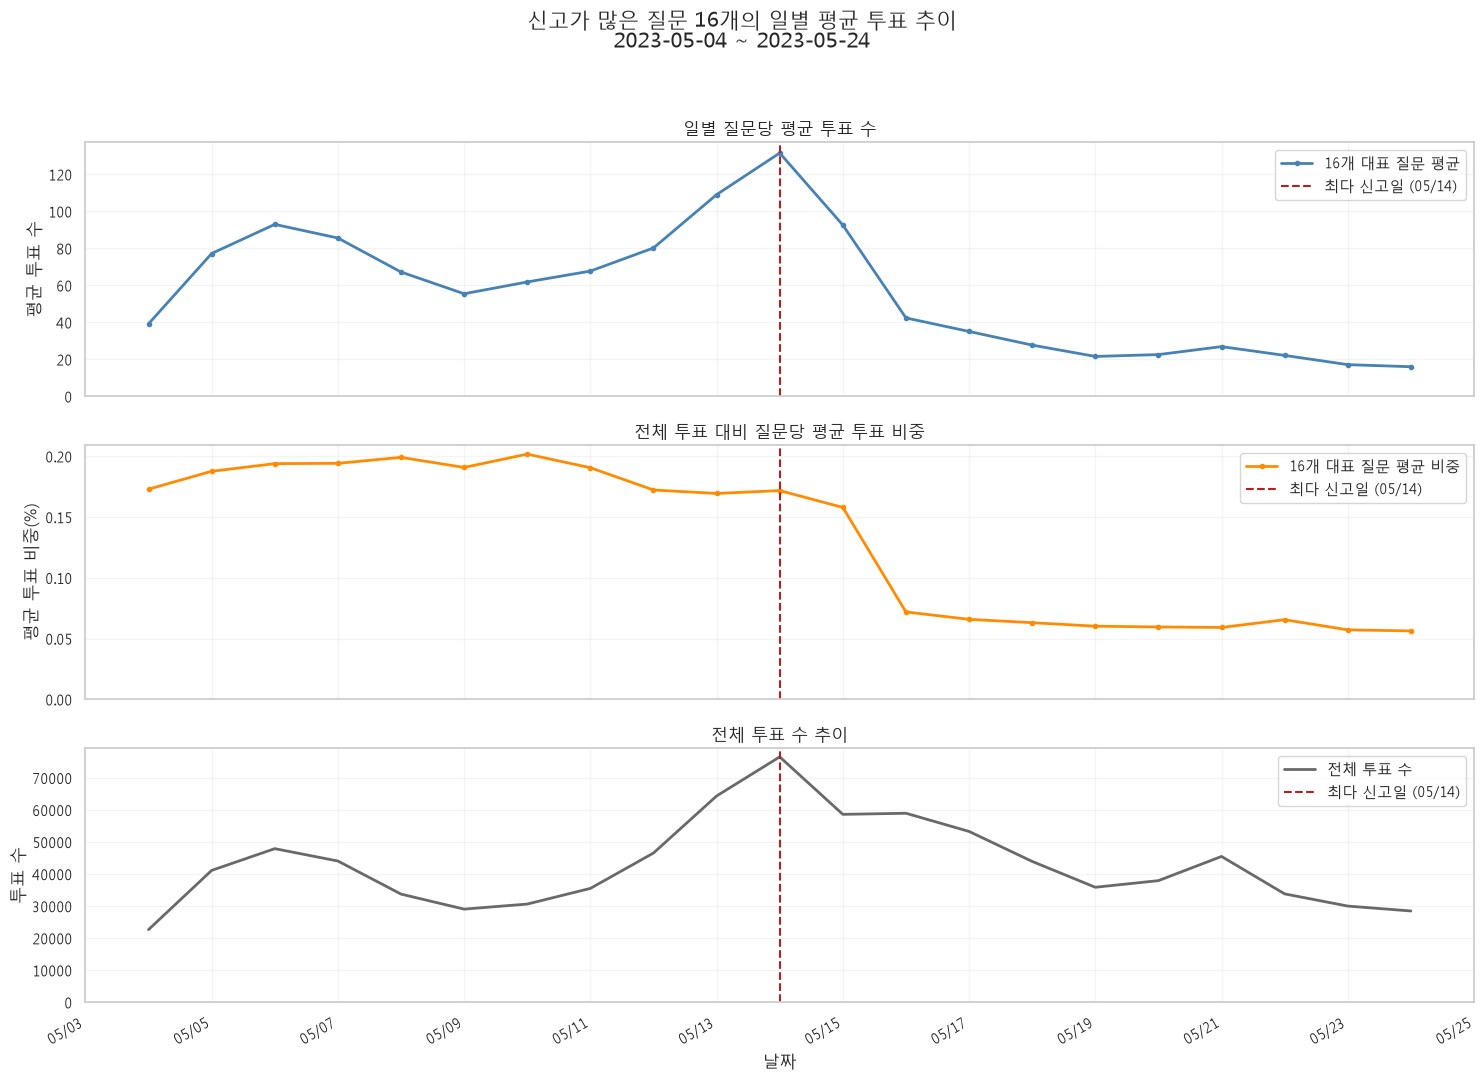

In [44]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# 그래프만 기준일 이후 10일까지 제한
graph_start = reference_date - pd.Timedelta(days=10)
graph_end = reference_date + pd.Timedelta(days=10)

df_plot = (
    df_daily_question_average.loc[
        df_daily_question_average["날짜"].between(
            graph_start, graph_end
        )
    ]
    .sort_values("날짜")
    .copy()
)

dates = df_plot["날짜"]
n_questions = len(question_ids)

fig, axes = plt.subplots(
    3, 1,
    figsize=(15, 11),
    sharex=True,
)

# 1. 질문당 평균 투표 수
axes[0].plot(
    dates,
    df_plot["질문당 평균 투표 수"],
    color="steelblue",
    marker="o",
    markersize=3,
    linewidth=2,
    label=f"{n_questions}개 대표 질문 평균",
)
axes[0].set_title("일별 질문당 평균 투표 수")
axes[0].set_ylabel("평균 투표 수")

# 2. 질문별 투표 비중의 일별 평균
axes[1].plot(
    dates,
    df_plot["질문당 평균 투표 비중(%)"],
    color="darkorange",
    marker="o",
    markersize=3,
    linewidth=2,
    label=f"{n_questions}개 대표 질문 평균 비중",
)
axes[1].set_title("전체 투표 대비 질문당 평균 투표 비중")
axes[1].set_ylabel("평균 투표 비중(%)")

# 3. 같은 기간 전체 투표 수
axes[2].plot(
    dates,
    df_plot["전체 투표 수"],
    color="dimgray",
    linewidth=2,
    label="전체 투표 수",
)
axes[2].set_title("전체 투표 수 추이")
axes[2].set_ylabel("투표 수")
axes[2].set_xlabel("날짜")
axes[2].ticklabel_format(
    axis="y", style="plain", useOffset=False
)

# 공통 기준일 표시
for ax in axes:
    ax.axvline(
        reference_date,
        color="firebrick",
        linestyle="--",
        linewidth=1.5,
        label=f"최다 신고일 ({reference_date:%m/%d})",
    )
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.2)
    ax.legend(loc="upper right")

axes[2].xaxis.set_major_locator(
    mdates.DayLocator(interval=2)
)
axes[2].xaxis.set_major_formatter(
    mdates.DateFormatter("%m/%d")
)

fig.suptitle(
    f"신고가 많은 질문 {n_questions}개의 일별 평균 투표 추이\n"
    f"{dates.min():%Y-%m-%d} ~ {dates.max():%Y-%m-%d}",
    fontsize=15,
)

fig.autofmt_xdate()
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

### 최다 신고일 전후 일별 투표에 등장한 고유 질문 수 변화

C:\Users\USER\AppData\Local\Temp\ipykernel_39600\2096640774.py:35: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  - pd.Timedelta(nanoseconds=1)


,날짜,투표에 등장한 고유 질문 수,전일 대비 증감
0,2023-05-04,460,<NA>
1,2023-05-05,460,0
2,2023-05-06,460,0
3,2023-05-07,460,0
4,2023-05-08,460,0
5,2023-05-09,460,0
6,2023-05-10,460,0
7,2023-05-11,547,87
8,2023-05-12,549,2
9,2023-05-13,549,0


C:\Users\USER\AppData\Local\Temp\ipykernel_39600\2096640774.py:63: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  graph_start = reference_date - pd.Timedelta(days=10)
C:\Users\USER\AppData\Local\Temp\ipykernel_39600\2096640774.py:64: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  graph_end = reference_date + pd.Timedelta(days=10)


공통 기준일: 2023-05-14
실제 표시 범위: 2023-05-04 ~ 2023-05-24


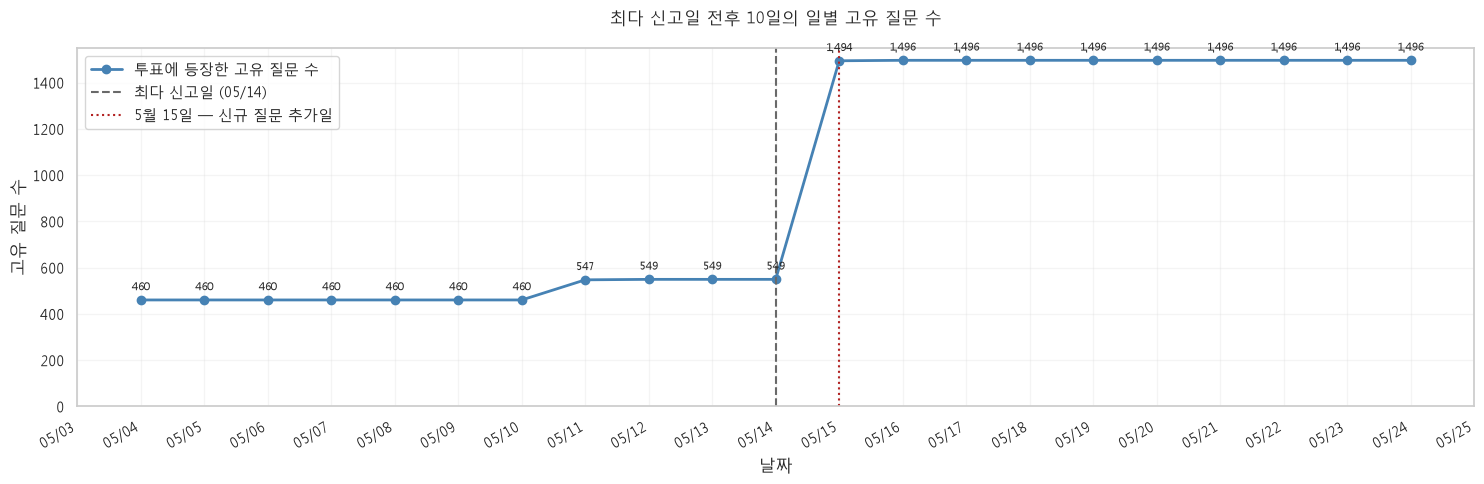

In [45]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import MaxNLocator

mapper = QuestionIdMapper()

# 1. 전체 투표 기록에 대표 질문 ID 적용
df_daily_unique_source = df_userquestionrecord[
    ["question_id", "created_at"]
].copy()

df_daily_unique_source["대표 질문 ID"] = mapper.transform(
    df_daily_unique_source["question_id"]
)

# mapper의 제외 대상 제거
df_daily_unique_source = df_daily_unique_source.dropna(
    subset=["대표 질문 ID"]
)

df_daily_unique_source["날짜"] = pd.to_datetime(
    df_daily_unique_source["created_at"]
).dt.normalize()

# 2. 표 집계 기간: 2023년 5월 중 조회 가능한 기간
unique_start = max(
    pd.Timestamp("2023-05-01"),
    pd.Timestamp(params["start_at"]).normalize(),
)
unique_end = min(
    pd.Timestamp("2023-05-31"),
    (
        pd.Timestamp(params["end_at"])
        - pd.Timedelta(nanoseconds=1)
    ).normalize(),
)

unique_dates = pd.date_range(
    unique_start, unique_end, freq="D"
)

# 3. 날짜별 고유 대표 질문 수
# 선정한 16개가 아닌 전체 질문 기준
df_daily_unique_questions = (
    df_daily_unique_source
    .groupby("날짜")["대표 질문 ID"]
    .nunique()
    .reindex(unique_dates, fill_value=0)
    .rename_axis("날짜")
    .reset_index(name="투표에 등장한 고유 질문 수")
)

df_daily_unique_questions["전일 대비 증감"] = (
    df_daily_unique_questions["투표에 등장한 고유 질문 수"]
    .diff()
    .astype("Int64")
)

display(df_daily_unique_questions)

# 4. 그래프는 앞선 셀의 최다 신고일 전후 10일
graph_start = reference_date - pd.Timedelta(days=10)
graph_end = reference_date + pd.Timedelta(days=10)

df_unique_plot = df_daily_unique_questions.loc[
    df_daily_unique_questions["날짜"].between(
        graph_start, graph_end
    )
].copy()

if df_unique_plot.empty:
    raise ValueError("그래프 표시 기간에 해당하는 데이터가 없습니다.")

print(f"공통 기준일: {reference_date:%Y-%m-%d}")
print(
    f"실제 표시 범위: "
    f"{df_unique_plot['날짜'].min():%Y-%m-%d}"
    f" ~ {df_unique_plot['날짜'].max():%Y-%m-%d}"
)

# 5. 그래프
fig, ax = plt.subplots(figsize=(15, 5))

ax.plot(
    df_unique_plot["날짜"],
    df_unique_plot["투표에 등장한 고유 질문 수"],
    color="steelblue",
    marker="o",
    linewidth=2,
    label="투표에 등장한 고유 질문 수",
)

for day, count in zip(
    df_unique_plot["날짜"],
    df_unique_plot["투표에 등장한 고유 질문 수"],
):
    ax.annotate(
        f"{count:,}",
        xy=(day, count),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        fontsize=8,
    )

ax.axvline(
    reference_date,
    color="dimgray",
    linestyle="--",
    label=f"최다 신고일 ({reference_date:%m/%d})",
)

ax.axvline(
    pd.Timestamp("2023-05-15"),
    color="firebrick",
    linestyle=":",
    linewidth=1.5,
    label="5월 15일 — 신규 질문 추가일",
)

ax.set_title(
    "최다 신고일 전후 10일의 일별 고유 질문 수\n"
)
ax.set_xlabel("날짜")
ax.set_ylabel("고유 질문 수")
ax.set_ylim(bottom=0)
ax.margins(y=0.15)

ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.xaxis.set_major_locator(mdates.DayLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%d"))

ax.grid(alpha=0.2)
ax.legend()
fig.autofmt_xdate()

plt.tight_layout()
plt.show()

### 신고가 많은 질문 16개의 일별 투표 비중과 신고 비중 간 상관관계

C:\Users\USER\AppData\Local\Temp\ipykernel_39600\1018049083.py:84: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  reference_date - pd.Timedelta(days=10),
C:\Users\USER\AppData\Local\Temp\ipykernel_39600\1018049083.py:85: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  reference_date + pd.Timedelta(days=10),


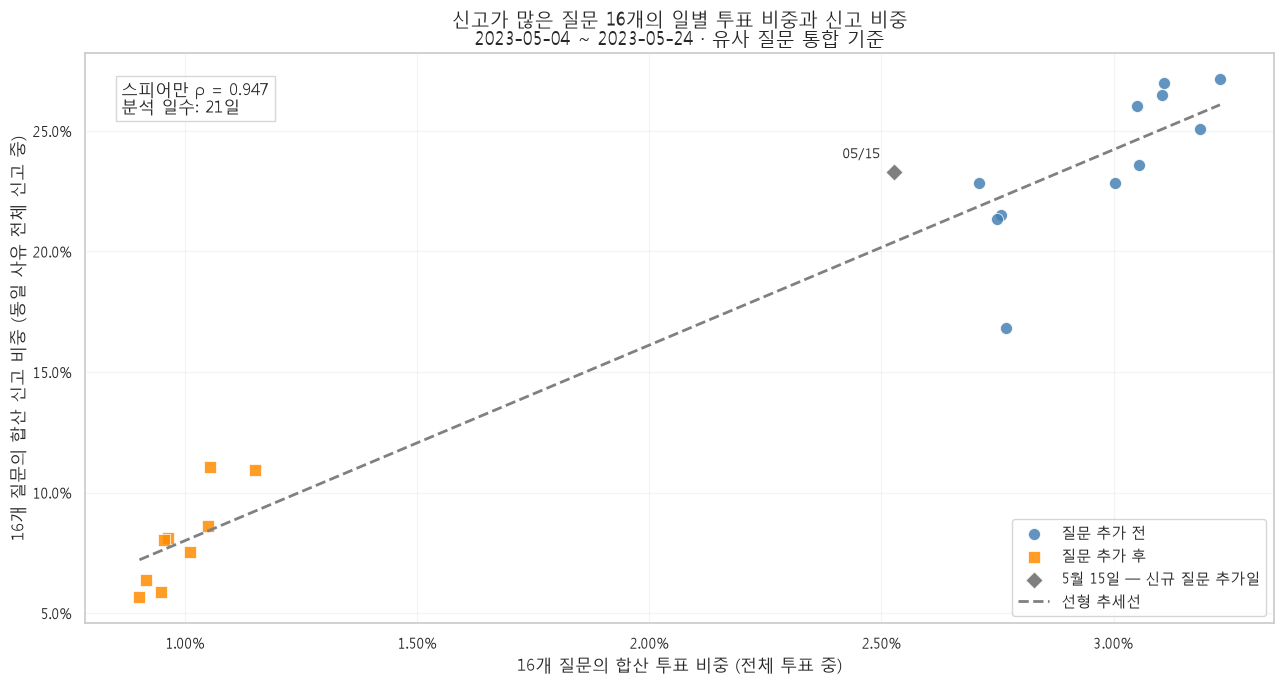

,날짜,16개 질문 합산 투표 수,전체 투표 수,선정 질문 신고 수,전체 신고 수,선정 질문 투표 비중(%),선정 질문 신고 비중(%)
0,2023-05-04,628,22692,18,107,2.767,16.822
1,2023-05-05,1236,41154,32,140,3.003,22.857
2,2023-05-06,1488,47940,153,578,3.104,26.471
3,2023-05-07,1370,44081,279,1034,3.108,26.983
4,2023-05-08,1076,33767,302,1205,3.187,25.062
5,2023-05-09,888,29078,313,1327,3.054,23.587
6,2023-05-10,990,30658,377,1389,3.229,27.142
7,2023-05-11,1084,35540,381,1463,3.050,26.042
8,2023-05-12,1284,46571,356,1654,2.757,21.524
9,2023-05-13,1745,64365,539,2358,2.711,22.858


In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# 앞선 집계 셀의 question_ids, target_reasons, reference_date 사용
n_questions = len(question_ids)
addition_date = pd.Timestamp("2023-05-15")

# 1. clean에서 지정 사유 7개의 신고만 포함
df_scatter_reports = df_questionreport_clean.loc[
    df_questionreport_clean["대표 질문 ID"].notna()
    & df_questionreport_clean["reason"]
        .astype("string")
        .str.strip()
        .isin(target_reasons)
].copy()

df_scatter_reports["날짜"] = pd.to_datetime(
    df_scatter_reports["created_at"]
).dt.normalize()

# 전체 신고 수: clean 전체 질문의 동일 사유 기준
daily_all_reports = (
    df_scatter_reports.groupby("날짜")
    .size()
    .rename("전체 신고 수")
)

# 선정한 16개 질문의 신고 수
daily_selected_reports = (
    df_scatter_reports.loc[
        df_scatter_reports["대표 질문 ID"].isin(question_ids)
    ]
    .groupby("날짜")
    .size()
    .rename("선정 질문 신고 수")
)

# 2. 기존 투표 집계에 신고 수 연결
vote_sum_col = f"{n_questions}개 질문 합산 투표 수"

df_scatter = df_daily_question_average[[
    "날짜",
    vote_sum_col,
    "전체 투표 수",
]].copy()

df_scatter["날짜"] = pd.to_datetime(
    df_scatter["날짜"]
).dt.normalize()

df_scatter = (
    df_scatter
    .merge(
        daily_all_reports,
        left_on="날짜",
        right_index=True,
        how="left",
        validate="one_to_one",
    )
    .merge(
        daily_selected_reports,
        left_on="날짜",
        right_index=True,
        how="left",
        validate="one_to_one",
    )
)

report_columns = ["전체 신고 수", "선정 질문 신고 수"]

df_scatter[report_columns] = (
    df_scatter[report_columns]
    .fillna(0)
    .astype("int64")
)

# 3. 최다 신고일 전후 10일
# 분모가 0인 날은 제외
df_scatter = (
    df_scatter.loc[
        df_scatter["날짜"].between(
            reference_date - pd.Timedelta(days=10),
            reference_date + pd.Timedelta(days=10),
        )
        & df_scatter["전체 투표 수"].gt(0)
        & df_scatter["전체 신고 수"].gt(0)
    ]
    .sort_values("날짜")
    .copy()
)

x_col = "선정 질문 투표 비중(%)"
y_col = "선정 질문 신고 비중(%)"

df_scatter[x_col] = (
    df_scatter[vote_sum_col]
    / df_scatter["전체 투표 수"]
    * 100
)

df_scatter[y_col] = (
    df_scatter["선정 질문 신고 수"]
    / df_scatter["전체 신고 수"]
    * 100
)

if len(df_scatter) < 2:
    raise ValueError("상관관계를 계산할 날짜가 부족합니다.")

# 4. 스피어만 상관계수
# 동점은 평균 순위로 처리
rho = (
    df_scatter[x_col].rank()
    .corr(df_scatter[y_col].rank())
)

# 5. 산점도
fig, ax = plt.subplots(figsize=(13, 7))

groups = [
    (
        df_scatter["날짜"].lt(addition_date),
        "질문 추가 전",
        "steelblue",
        "o",
    ),
    (
        df_scatter["날짜"].gt(addition_date),
        "질문 추가 후",
        "darkorange",
        "s",
    ),
    (
        df_scatter["날짜"].eq(addition_date),
        "5월 15일 — 신규 질문 추가일",
        "dimgray",
        "D",
    ),
]

for mask, label, color, marker in groups:
    subset = df_scatter.loc[mask]

    if subset.empty:
        continue

    ax.scatter(
        subset[x_col],
        subset[y_col],
        color=color,
        marker=marker,
        s=75,
        alpha=0.85,
        edgecolors="white",
        linewidths=0.6,
        label=label,
    )

# 6. 선형 추세선 — 원래 비중 값에 적합
if df_scatter[x_col].nunique() >= 2:
    slope, intercept = np.polyfit(
        df_scatter[x_col],
        df_scatter[y_col],
        deg=1,
    )

    x_line = np.linspace(
        df_scatter[x_col].min(),
        df_scatter[x_col].max(),
        100,
    )

    ax.plot(
        x_line,
        slope * x_line + intercept,
        color="gray",
        linestyle="--",
        linewidth=2,
        label="선형 추세선",
    )

# 신규 질문 추가일 표시
for _, row in df_scatter.loc[
    df_scatter["날짜"].eq(addition_date)
].iterrows():
    ax.annotate(
        "05/15",
        xy=(row[x_col], row[y_col]),
        xytext=(-10, 10),
        textcoords="offset points",
        ha="right",
        fontsize=10,
    )

rho_text = f"{rho:.3f}" if pd.notna(rho) else "계산 불가"

ax.text(
    0.03,
    0.95,
    f"스피어만 ρ = {rho_text}\n"
    f"분석 일수: {len(df_scatter)}일",
    transform=ax.transAxes,
    va="top",
    fontsize=12,
    bbox=dict(
        facecolor="white",
        edgecolor="lightgray",
        alpha=0.9,
    ),
)

ax.set_title(
    f"신고가 많은 질문 {n_questions}개의 "
    "일별 투표 비중과 신고 비중\n"
    f"{df_scatter['날짜'].min():%Y-%m-%d}"
    f" ~ {df_scatter['날짜'].max():%Y-%m-%d}"
    " · 유사 질문 통합 기준",
    fontsize=14,
)

ax.set_xlabel(
    f"{n_questions}개 질문의 합산 투표 비중 (전체 투표 중)"
)
ax.set_ylabel(
    f"{n_questions}개 질문의 합산 신고 비중 "
    "(동일 사유 전체 신고 중)"
)

ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))

ax.grid(alpha=0.2)
ax.set_axisbelow(True)
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

# 산점도에 사용한 일별 데이터
display(
    df_scatter[[
        "날짜",
        vote_sum_col,
        "전체 투표 수",
        "선정 질문 신고 수",
        "전체 신고 수",
        x_col,
        y_col,
    ]].round(3)
)

## 질문 라벨링

### 라벨링 한 결과 가져오기

In [73]:
from pathlib import Path
import pandas as pd

csv_path = Path.cwd() / "대표질문_통합목록_최종_긍정부정_라벨링_수정본.csv"

df_labels = pd.read_csv(csv_path, encoding="utf-8-sig")

### 각 카테고리 별 신고율

In [77]:
import pandas as pd

target_reasons = [
    "그냥 싫어",
    "나랑 맞지 않는 질문인 것 같음",
    "불쾌한 질문 내용",
    "이 질문은 재미없어요",
    "기타",
    "불쾌한 내용이 포함되어 있음",
    "선정적이거나 자극적인 질문",
]

# 1. CSV의 질문별 라벨
df_question_reports = df_labels[[
    "대표 질문 ID",
    "대표 질문명",
    "긍정 분류",
    "부정 분류",
]].copy()

df_question_reports["대표 질문 ID"] = pd.to_numeric(
    df_question_reports["대표 질문 ID"],
    errors="raise",
).astype("Int64")

if (
    df_question_reports["대표 질문 ID"].isna().any()
    or df_question_reports["대표 질문 ID"].duplicated().any()
):
    raise ValueError("대표 질문 ID의 결측·중복을 확인해 주세요.")


def has_label(series):
    return (
        series.fillna("")
        .astype("string")
        .str.split(",")
        .apply(
            lambda labels: any(
                label.strip() not in ["", "해당 없음"]
                for label in labels
            )
        )
    )


positive = has_label(df_question_reports["긍정 분류"])
negative = has_label(df_question_reports["부정 분류"])

# 2. 서로 겹치지 않는 세 집단으로 구분
df_question_reports["그룹"] = "라벨 없음"

df_question_reports.loc[
    positive & ~negative, "그룹"
] = "긍정만"

df_question_reports.loc[
    ~positive & negative, "그룹"
] = "부정만"

df_question_reports.loc[
    positive & negative, "그룹"
] = "긍정·부정 모두"

# 3. 대표 질문별 지정 사유 신고 건수
report_counts = (
    df_questionreport_clean.loc[
        df_questionreport_clean["reason"]
        .astype("string")
        .str.strip()
        .isin(target_reasons)
    ]
    .groupby("대표 질문 ID")["id"]
    .nunique()
    .rename("신고 수")
    .reset_index()
)

# 4. 신고 없는 질문도 0건으로 포함
df_question_reports = df_question_reports.merge(
    report_counts,
    on="대표 질문 ID",
    how="left",
    validate="one_to_one",
)

df_question_reports["신고 수"] = (
    df_question_reports["신고 수"]
    .fillna(0)
    .astype("int64")
)

# 5. 집단별 신고 합계·평균
group_order = ["긍정만", "부정만", "긍정·부정 모두"]

df_group_report_summary = (
    df_question_reports.loc[
        df_question_reports["그룹"].isin(group_order)
    ]
    .groupby("그룹")
    .agg(
        전체_질문_수=("대표 질문 ID", "size"),
        신고_합계=("신고 수", "sum"),
        질문당_평균_신고_건수=("신고 수", "mean"),
    )
    .reindex(group_order)
    .reset_index()
    .rename(columns={
        "전체_질문_수": "전체 질문 수",
        "신고_합계": "신고 합계",
        "질문당_평균_신고_건수": "질문당 평균 신고 건수",
    })
)

display(df_group_report_summary.round(2))

,그룹,전체 질문 수,신고 합계,질문당 평균 신고 건수
0,긍정만,2787,24860,8.92
1,부정만,37,658,17.78
2,긍정·부정 모두,954,17702,18.56


In [79]:
# 1. 지정 사유 7개의 신고에 질문 그룹 연결
df_group_report_reasons = (
    df_questionreport_clean.loc[
        df_questionreport_clean["reason"]
        .astype("string")
        .str.strip()
        .isin(target_reasons),
        ["id", "대표 질문 ID", "reason"],
    ]
    .copy()
    .merge(
        df_question_reports[["대표 질문 ID", "그룹"]],
        on="대표 질문 ID",
        how="inner",
        validate="many_to_one",
    )
)

df_group_report_reasons["reason"] = (
    df_group_report_reasons["reason"]
    .astype("string")
    .str.strip()
)

# 2. 집단별 신고 사유 건수·비율
group_order = ["긍정만", "부정만", "긍정·부정 모두"]

df_group_reason_summary = (
    df_group_report_reasons
    .groupby(["그룹", "reason"])["id"]
    .nunique()
    .reset_index(name="신고 수")
    .rename(columns={"reason": "신고 사유"})
)

df_group_reason_summary["그룹 내 비율(%)"] = (
    df_group_reason_summary["신고 수"]
    / df_group_reason_summary
        .groupby("그룹")["신고 수"]
        .transform("sum")
    * 100
)

# 3. 집단별 사유 순위 출력
for group in group_order:
    result = (
        df_group_reason_summary.loc[
            df_group_reason_summary["그룹"].eq(group)
        ]
        .sort_values(
            ["신고 수", "신고 사유"],
            ascending=[False, True],
        )
        .reset_index(drop=True)
    )

    print(f"\n[{group}] 신고 사유 순위")
    display(
        result[[
            "신고 사유",
            "신고 수",
            "그룹 내 비율(%)",
        ]].round(2)
    )


[긍정만] 신고 사유 순위


,신고 사유,신고 수,그룹 내 비율(%)
0,그냥 싫어,16994,68.36
1,나랑 맞지 않는 질문인 것 같음,5626,22.63
2,불쾌한 질문 내용,2104,8.46
3,기타,64,0.26
4,이 질문은 재미없어요,44,0.18
5,불쾌한 내용이 포함되어 있음,24,0.10
6,선정적이거나 자극적인 질문,4,0.02



[부정만] 신고 사유 순위


,신고 사유,신고 수,그룹 내 비율(%)
0,그냥 싫어,378,57.45
1,불쾌한 질문 내용,158,24.01
2,나랑 맞지 않는 질문인 것 같음,121,18.39
3,불쾌한 내용이 포함되어 있음,1,0.15



[긍정·부정 모두] 신고 사유 순위


,신고 사유,신고 수,그룹 내 비율(%)
0,그냥 싫어,10806,61.04
1,나랑 맞지 않는 질문인 것 같음,3688,20.83
2,불쾌한 질문 내용,3089,17.45
3,이 질문은 재미없어요,48,0.27
4,불쾌한 내용이 포함되어 있음,47,0.27
5,기타,19,0.11
6,선정적이거나 자극적인 질문,5,0.03


### 카테고리별 신고율

In [87]:
import pandas as pd

# 1. 질문별 세부 카테고리
def split_labels(value):
    if pd.isna(value):
        return []

    return list(dict.fromkeys(
        label.strip()
        for label in str(value).split(",")
        if label.strip() not in ["", "해당 없음"]
    ))


group_order = ["긍정만", "부정만", "긍정·부정 모두"]
category_parts = []

for group in group_order:
    part = df_question_reports.loc[
        df_question_reports["그룹"].eq(group),
        [
            "대표 질문 ID",
            "그룹",
            "긍정 분류",
            "부정 분류",
            "신고 수",
        ],
    ].copy()

    if group == "긍정만":
        part["카테고리"] = part["긍정 분류"].apply(split_labels)

    elif group == "부정만":
        part["카테고리"] = part["부정 분류"].apply(split_labels)

    else:
        part["카테고리"] = [
            list(dict.fromkeys(
                split_labels(positive) + split_labels(negative)
            ))
            for positive, negative in zip(
                part["긍정 분류"],
                part["부정 분류"],
            )
        ]

    category_parts.append(part)

df_category_questions = (
    pd.concat(category_parts, ignore_index=True)
    .explode("카테고리")
    .dropna(subset=["카테고리"])
    .drop_duplicates(["대표 질문 ID", "카테고리"])
)

# 2. 카테고리별 신고 현황 — 신고 없는 질문도 0건으로 포함
df_category_report_summary = (
    df_category_questions
    .groupby(["그룹", "카테고리"])
    .agg(
        전체_질문_수=("대표 질문 ID", "nunique"),
        신고_있는_질문_수=(
            "신고 수", lambda s: s.gt(0).sum()
        ),
        신고_합계=("신고 수", "sum"),
        질문당_평균_신고_건수=("신고 수", "mean"),
    )
    .reset_index()
    .rename(columns={
        "전체_질문_수": "전체 질문 수",
        "신고_있는_질문_수": "신고 있는 질문 수",
        "신고_합계": "신고 합계",
        "질문당_평균_신고_건수": "질문당 평균 신고 건수",
    })
)

# 3. 집단별 결과 표시
for group in group_order:
    summary = (
        df_category_report_summary.loc[
            df_category_report_summary["그룹"].eq(group)
        ]
        .sort_values(
            ["질문당 평균 신고 건수", "신고 합계"],
            ascending=[False, False],
        )
        .reset_index(drop=True)
    )

    print(f"\n[{group}] 카테고리별 신고 현황")
    display(summary.drop(columns="그룹").round(2))


[긍정만] 카테고리별 신고 현황


,카테고리,전체 질문 수,신고 있는 질문 수,신고 합계,질문당 평균 신고 건수
0,행실,36,28,489,13.58
1,매력,327,249,3842,11.75
2,팩트,34,23,392,11.53
3,What if?,98,72,1048,10.69
4,재능,438,315,4478,10.22
5,이성적 호감,146,118,1471,10.08
6,신체 외형,210,155,2023,9.63
7,성격,311,215,2904,9.34
8,취향,130,91,1022,7.86
9,호감,800,585,6274,7.84



[부정만] 카테고리별 신고 현황


,카테고리,전체 질문 수,신고 있는 질문 수,신고 합계,질문당 평균 신고 건수
0,신체 외형,1,1,327,327.00
1,What if?,2,2,73,36.50
2,재능,10,6,135,13.50
3,행실,10,8,106,10.60
4,식탐,2,2,7,3.50
5,성향,12,6,10,0.83



[긍정·부정 모두] 카테고리별 신고 현황


,카테고리,전체 질문 수,신고 있는 질문 수,신고 합계,질문당 평균 신고 건수
0,식탐,13,12,1164,89.54
1,체취,20,16,1586,79.30
2,재능,13,10,741,57.00
3,행위,17,13,565,33.24
4,신체 접촉,37,33,1042,28.16
5,신체 외형,170,133,4245,24.97
6,취향,60,51,1329,22.15
7,성격,165,132,2957,17.92
8,이성적 호감,100,81,1787,17.87
9,행실,22,19,325,14.77


#### 카테고리별 신고 분포도

분석 대상 질문 수: 800개
지정 사유 신고 합계: 6,274건


,질문당 신고 건수
count,800.00
mean,7.84
std,11.11
min,0.00
25%,0.00
50%,2.00
75%,12.00
90%,26.00
95%,32.05
99%,43.02


,질문당 신고 건수,질문 수
0,0,215
1,1,165
2,2,77
3,3,23
4,4,6
...,...,...
68,68,0
69,69,0
70,70,0
71,71,0


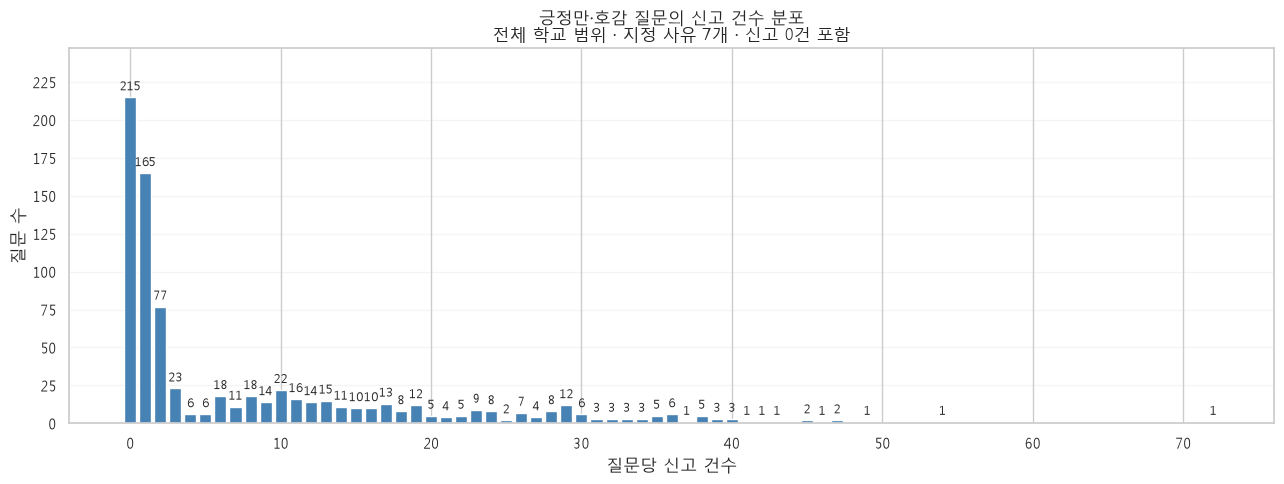

In [93]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

target_reasons = [
    "그냥 싫어",
    "나랑 맞지 않는 질문인 것 같음",
    "불쾌한 질문 내용",
    "이 질문은 재미없어요",
    "기타",
    "불쾌한 내용이 포함되어 있음",
    "선정적이거나 자극적인 질문",
]


def split_labels(value):
    if pd.isna(value):
        return []

    return list(dict.fromkeys(
        label.strip()
        for label in str(value).split(",")
        if label.strip() not in ["", "해당 없음"]
    ))


# 1. 전체 라벨 CSV에서 긍정만·호감 질문 선별
df_all_label_questions = df_labels[[
    "대표 질문 ID",
    "대표 질문명",
    "긍정 분류",
    "부정 분류",
]].copy()

df_all_label_questions["대표 질문 ID"] = pd.to_numeric(
    df_all_label_questions["대표 질문 ID"],
    errors="raise",
).astype("Int64")

if (
    df_all_label_questions["대표 질문 ID"].isna().any()
    or df_all_label_questions["대표 질문 ID"].duplicated().any()
):
    raise ValueError("대표 질문 ID의 결측·중복을 확인해 주세요.")

positive_labels = (
    df_all_label_questions["긍정 분류"].apply(split_labels)
)
negative_labels = (
    df_all_label_questions["부정 분류"].apply(split_labels)
)

df_positive_affection_reports_all = (
    df_all_label_questions.loc[
        positive_labels.apply(lambda labels: "호감" in labels)
        & negative_labels.apply(len).eq(0)
    ]
    .copy()
)

# 2. 전체 학교 범위의 지정 사유 신고 집계
# 투표 유저 여부로 제한하지 않음
all_report_counts = (
    df_questionreport_clean.loc[
        df_questionreport_clean["reason"]
        .astype("string")
        .str.strip()
        .isin(target_reasons)
    ]
    .groupby("대표 질문 ID")["id"]
    .nunique()
    .reset_index(name="신고 수")
)

# 3. 신고가 없는 질문도 0건으로 포함
df_positive_affection_reports_all = (
    df_positive_affection_reports_all
    .merge(
        all_report_counts,
        on="대표 질문 ID",
        how="left",
        validate="one_to_one",
    )
)

df_positive_affection_reports_all["신고 수"] = (
    df_positive_affection_reports_all["신고 수"]
    .fillna(0)
    .astype("int64")
)

if df_positive_affection_reports_all.empty:
    raise ValueError("긍정만·호감에 해당하는 질문이 없습니다.")

counts = df_positive_affection_reports_all["신고 수"]

# 4. 기초 통계
print(f"분석 대상 질문 수: {len(counts):,}개")
print(f"지정 사유 신고 합계: {counts.sum():,}건")

display(
    counts.describe(
        percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
    )
    .to_frame("질문당 신고 건수")
    .round(2)
)

# 5. 신고 건수별 질문 수
df_affection_report_distribution_all = (
    counts.value_counts()
    .reindex(range(int(counts.max()) + 1), fill_value=0)
    .sort_index()
    .rename_axis("질문당 신고 건수")
    .reset_index(name="질문 수")
)

display(df_affection_report_distribution_all)

# 6. 분포 그래프
fig, ax = plt.subplots(figsize=(13, 5))

bars = ax.bar(
    df_affection_report_distribution_all["질문당 신고 건수"],
    df_affection_report_distribution_all["질문 수"],
    color="steelblue",
)

for bar in bars:
    height = bar.get_height()

    if height > 0:
        ax.annotate(
            f"{int(height):,}",
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            fontsize=9,
        )

ax.set_title(
    "긍정만·호감 질문의 신고 건수 분포\n"
    "전체 학교 범위 · 지정 사유 7개 · 신고 0건 포함"
)
ax.set_xlabel("질문당 신고 건수")
ax.set_ylabel("질문 수")

ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.yaxis.set_major_locator(MaxNLocator(integer=True))

ax.margins(y=0.15)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

분석 대상 질문 수: 254개
지정 사유 신고 합계: 2,773건


,질문당 신고 건수
count,254.00
mean,10.92
std,25.81
min,0.00
25%,1.00
50%,2.00
75%,13.00
90%,26.00
95%,47.75
99%,178.52


,질문당 신고 건수,질문 수
0,0,57
1,1,61
2,2,30
3,3,15
4,4,4
...,...,...
194,194,0
195,195,0
196,196,0
197,197,0


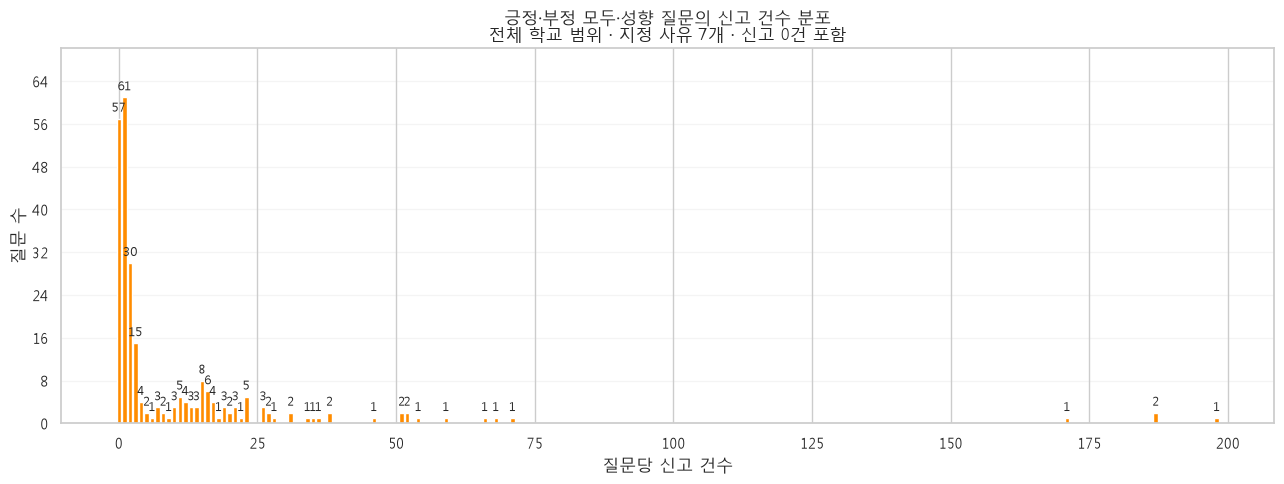

In [94]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

target_reasons = [
    "그냥 싫어",
    "나랑 맞지 않는 질문인 것 같음",
    "불쾌한 질문 내용",
    "이 질문은 재미없어요",
    "기타",
    "불쾌한 내용이 포함되어 있음",
    "선정적이거나 자극적인 질문",
]


def split_labels(value):
    if pd.isna(value):
        return []

    return list(dict.fromkeys(
        label.strip()
        for label in str(value).split(",")
        if label.strip() not in ["", "해당 없음"]
    ))


# 1. 전체 라벨 데이터
df_both_tendency = df_labels[[
    "대표 질문 ID",
    "대표 질문명",
    "긍정 분류",
    "부정 분류",
]].copy()

df_both_tendency["대표 질문 ID"] = pd.to_numeric(
    df_both_tendency["대표 질문 ID"],
    errors="raise",
).astype("Int64")

if (
    df_both_tendency["대표 질문 ID"].isna().any()
    or df_both_tendency["대표 질문 ID"].duplicated().any()
):
    raise ValueError("대표 질문 ID의 결측·중복을 확인해 주세요.")

positive_labels = df_both_tendency["긍정 분류"].apply(split_labels)
negative_labels = df_both_tendency["부정 분류"].apply(split_labels)

# 긍정·부정 모두 부여 + 한쪽 이상에 성향 포함
both_mask = (
    positive_labels.apply(len).gt(0)
    & negative_labels.apply(len).gt(0)
)

tendency_mask = (
    positive_labels.apply(lambda labels: "성향" in labels)
    | negative_labels.apply(lambda labels: "성향" in labels)
)

df_both_tendency = df_both_tendency.loc[
    both_mask & tendency_mask
].copy()

# 2. 전체 학교 범위의 지정 사유 신고 수
report_counts = (
    df_questionreport_clean.loc[
        df_questionreport_clean["reason"]
        .astype("string")
        .str.strip()
        .isin(target_reasons)
    ]
    .groupby("대표 질문 ID")["id"]
    .nunique()
    .reset_index(name="신고 수")
)

df_both_tendency = df_both_tendency.merge(
    report_counts,
    on="대표 질문 ID",
    how="left",
    validate="one_to_one",
)

df_both_tendency["신고 수"] = (
    df_both_tendency["신고 수"]
    .fillna(0)
    .astype("int64")
)

if df_both_tendency.empty:
    raise ValueError("해당 조건의 질문이 없습니다.")

counts = df_both_tendency["신고 수"]

# 3. 기초 통계
print(f"분석 대상 질문 수: {len(counts):,}개")
print(f"지정 사유 신고 합계: {counts.sum():,}건")

display(
    counts.describe(
        percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
    )
    .to_frame("질문당 신고 건수")
    .round(2)
)

# 4. 신고 건수별 질문 수
df_both_tendency_distribution = (
    counts.value_counts()
    .reindex(range(int(counts.max()) + 1), fill_value=0)
    .sort_index()
    .rename_axis("질문당 신고 건수")
    .reset_index(name="질문 수")
)

display(df_both_tendency_distribution)

# 5. 분포 그래프
fig, ax = plt.subplots(figsize=(13, 5))

bars = ax.bar(
    df_both_tendency_distribution["질문당 신고 건수"],
    df_both_tendency_distribution["질문 수"],
    color="darkorange",
)

for bar in bars:
    height = bar.get_height()

    if height > 0:
        ax.annotate(
            f"{int(height):,}",
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            fontsize=9,
        )

ax.set_title(
    "긍정·부정 모두·성향 질문의 신고 건수 분포\n"
    "전체 학교 범위 · 지정 사유 7개 · 신고 0건 포함"
)
ax.set_xlabel("질문당 신고 건수")
ax.set_ylabel("질문 수")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.margins(y=0.15)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

분석 대상 질문 수: 37개
지정 사유 신고 합계: 658건


,질문당 신고 건수
count,37.00
mean,17.78
std,55.06
min,0.00
25%,0.00
50%,1.00
75%,5.00
90%,32.80
95%,65.60
99%,235.20


,질문당 신고 건수,질문 수
0,0,12
1,1,7
2,2,5
3,3,2
4,4,0
...,...,...
323,323,0
324,324,0
325,325,0
326,326,0


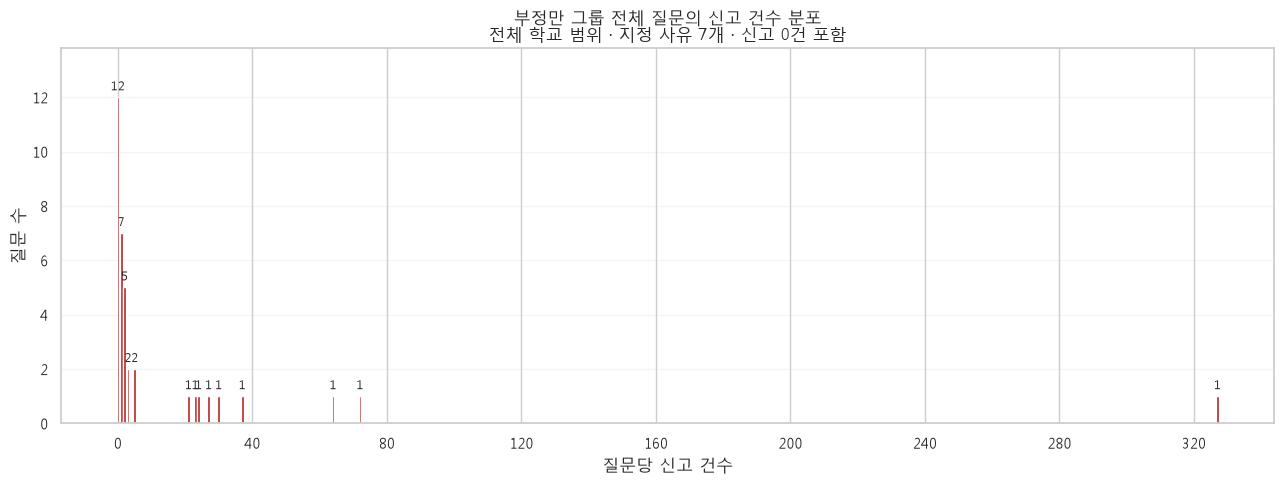

In [96]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

target_reasons = [
    "그냥 싫어",
    "나랑 맞지 않는 질문인 것 같음",
    "불쾌한 질문 내용",
    "이 질문은 재미없어요",
    "기타",
    "불쾌한 내용이 포함되어 있음",
    "선정적이거나 자극적인 질문",
]


def split_labels(value):
    if pd.isna(value):
        return []

    return list(dict.fromkeys(
        label.strip()
        for label in str(value).split(",")
        if label.strip() not in ["", "해당 없음"]
    ))


# 1. 긍정 라벨은 없고 부정 라벨만 있는 질문
df_negative_only = df_labels[[
    "대표 질문 ID",
    "대표 질문명",
    "긍정 분류",
    "부정 분류",
]].copy()

df_negative_only["대표 질문 ID"] = pd.to_numeric(
    df_negative_only["대표 질문 ID"],
    errors="raise",
).astype("Int64")

if (
    df_negative_only["대표 질문 ID"].isna().any()
    or df_negative_only["대표 질문 ID"].duplicated().any()
):
    raise ValueError("대표 질문 ID의 결측·중복을 확인해 주세요.")

positive_labels = df_negative_only["긍정 분류"].apply(split_labels)
negative_labels = df_negative_only["부정 분류"].apply(split_labels)

df_negative_only = df_negative_only.loc[
    positive_labels.apply(len).eq(0)
    & negative_labels.apply(len).gt(0)
].copy()

# 2. 전체 학교 범위의 질문별 신고 수
report_counts = (
    df_questionreport_clean.loc[
        df_questionreport_clean["reason"]
        .astype("string")
        .str.strip()
        .isin(target_reasons)
    ]
    .groupby("대표 질문 ID")["id"]
    .nunique()
    .reset_index(name="신고 수")
)

df_negative_only = df_negative_only.merge(
    report_counts,
    on="대표 질문 ID",
    how="left",
    validate="one_to_one",
)

df_negative_only["신고 수"] = (
    df_negative_only["신고 수"]
    .fillna(0)
    .astype("int64")
)

if df_negative_only.empty:
    raise ValueError("부정만 그룹에 해당하는 질문이 없습니다.")

counts = df_negative_only["신고 수"]

# 3. 기초 통계
print(f"분석 대상 질문 수: {len(counts):,}개")
print(f"지정 사유 신고 합계: {counts.sum():,}건")

display(
    counts.describe(
        percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
    )
    .to_frame("질문당 신고 건수")
    .round(2)
)

# 4. 신고 건수별 질문 수 — 신고 0건 포함
df_negative_only_distribution = (
    counts.value_counts()
    .reindex(range(int(counts.max()) + 1), fill_value=0)
    .sort_index()
    .rename_axis("질문당 신고 건수")
    .reset_index(name="질문 수")
)

display(df_negative_only_distribution)

# 5. 분포 그래프
fig, ax = plt.subplots(figsize=(13, 5))

bars = ax.bar(
    df_negative_only_distribution["질문당 신고 건수"],
    df_negative_only_distribution["질문 수"],
    color="firebrick",
)

for bar in bars:
    height = bar.get_height()

    if height > 0:
        ax.annotate(
            f"{int(height):,}",
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            fontsize=9,
        )

ax.set_title(
    "부정만 그룹 전체 질문의 신고 건수 분포\n"
    "전체 학교 범위 · 지정 사유 7개 · 신고 0건 포함"
)
ax.set_xlabel("질문당 신고 건수")
ax.set_ylabel("질문 수")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.margins(y=0.15)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

#### 성별 카테고리 신고

In [99]:
import pandas as pd

target_reasons = [
    "그냥 싫어",
    "나랑 맞지 않는 질문인 것 같음",
    "불쾌한 질문 내용",
    "이 질문은 재미없어요",
    "기타",
    "불쾌한 내용이 포함되어 있음",
    "선정적이거나 자극적인 질문",
]


def split_labels(value):
    if pd.isna(value):
        return []

    return list(dict.fromkeys(
        label.strip()
        for label in str(value).split(",")
        if label.strip() not in ["", "해당 없음"]
    ))


# 1. 질문별 카테고리
# 긍정·부정 라벨을 합치되 동일 라벨은 한 번만 반영
df_gender_category_map = df_labels[[
    "대표 질문 ID",
    "긍정 분류",
    "부정 분류",
]].copy()

df_gender_category_map["대표 질문 ID"] = pd.to_numeric(
    df_gender_category_map["대표 질문 ID"],
    errors="raise",
).astype("Int64")

if (
    df_gender_category_map["대표 질문 ID"].isna().any()
    or df_gender_category_map["대표 질문 ID"].duplicated().any()
):
    raise ValueError("라벨 CSV의 대표 질문 ID 결측·중복을 확인해 주세요.")

df_gender_category_map["카테고리"] = [
    list(dict.fromkeys(
        split_labels(pos) + split_labels(neg)
    ))
    for pos, neg in zip(
        df_gender_category_map["긍정 분류"],
        df_gender_category_map["부정 분류"],
    )
]

df_gender_category_map = (
    df_gender_category_map[["대표 질문 ID", "카테고리"]]
    .explode("카테고리")
    .dropna(subset=["카테고리"])
    .drop_duplicates(["대표 질문 ID", "카테고리"])
)

# 2. 지정 사유 신고에 신고자의 성별 연결
df_gender_category_reports = (
    df_questionreport_clean.loc[
        df_questionreport_clean["reason"]
        .astype("string")
        .str.strip()
        .isin(target_reasons),
        ["id", "user_id", "대표 질문 ID"],
    ]
    .drop_duplicates("id")
    .merge(
        df_user[["id", "gender"]].rename(
            columns={"id": "user_id"}
        ),
        on="user_id",
        how="left",
        validate="many_to_one",
    )
)

df_gender_category_reports["성별"] = (
    df_gender_category_reports["gender"]
    .map({"F": "여학생", "M": "남학생"})
    .fillna("확인 불가")
)

print(
    "신고자 성별 확인 불가:",
    f"{df_gender_category_reports['성별'].eq('확인 불가').sum():,}건",
)

# 카테고리가 있는 질문의 신고만 분석
df_gender_category_base = (
    df_gender_category_reports.loc[
        df_gender_category_reports["대표 질문 ID"].isin(
            df_gender_category_map["대표 질문 ID"]
        )
    ]
    .copy()
)

print(
    "카테고리 연결 불가 신고:",
    f"{len(df_gender_category_reports) - len(df_gender_category_base):,}건",
)

# 성별 전체 신고 건수 — 카테고리로 펼치기 전에 계산
gender_report_totals = (
    df_gender_category_base
    .groupby("성별")["id"]
    .nunique()
    .rename("성별 전체 신고 수")
    .reset_index()
)

# 3. 신고 기록을 카테고리별로 연결
df_gender_category_detail = df_gender_category_base.merge(
    df_gender_category_map,
    on="대표 질문 ID",
    how="inner",
    validate="many_to_many",
)

# 4. 성별·카테고리별 집계
df_gender_category_summary = (
    df_gender_category_detail
    .groupby(["성별", "카테고리"])
    .agg(
        신고_수=("id", "nunique"),
        고유_신고자_수=("user_id", "nunique"),
        신고된_질문_수=("대표 질문 ID", "nunique"),
    )
    .reset_index()
    .rename(columns={
        "신고_수": "신고 수",
        "고유_신고자_수": "고유 신고자 수",
        "신고된_질문_수": "신고된 질문 수",
    })
    .merge(
        gender_report_totals,
        on="성별",
        how="left",
        validate="many_to_one",
    )
)

df_gender_category_summary["성별 신고 중 비중(%)"] = (
    df_gender_category_summary["신고 수"]
    / df_gender_category_summary["성별 전체 신고 수"]
    * 100
)

# 5. 성별로 각각 출력
for gender in ["여학생", "남학생"]:
    result = (
        df_gender_category_summary.loc[
            df_gender_category_summary["성별"].eq(gender)
        ]
        .sort_values(
            ["신고 수", "고유 신고자 수", "카테고리"],
            ascending=[False, False, True],
        )
        .reset_index(drop=True)
    )

    print(f"\n[{gender}] 신고가 집중된 카테고리")
    display(
        result[[
            "카테고리",
            "신고 수",
            "고유 신고자 수",
            "신고된 질문 수",
            "성별 신고 중 비중(%)",
        ]].round(2)
    )

신고자 성별 확인 불가: 0건
카테고리 연결 불가 신고: 0건

[여학생] 신고가 집중된 카테고리


,카테고리,신고 수,고유 신고자 수,신고된 질문 수,성별 신고 중 비중(%)
0,신체 외형,4859,3264,267,16.44
1,호감,4616,2603,576,15.62
2,성격,4159,2353,323,14.07
3,재능,3847,2239,308,13.02
4,성향,3741,2197,440,12.66
5,매력,2954,1845,281,10.00
6,이성적 호감,1860,1360,176,6.29
7,취향,1756,1191,122,5.94
8,체취,1043,843,15,3.53
9,식탐,951,718,13,3.22



[남학생] 신고가 집중된 카테고리


,카테고리,신고 수,고유 신고자 수,신고된 질문 수,성별 신고 중 비중(%)
0,호감,2629,1724,476,19.23
1,신체 외형,1736,1253,208,12.70
2,성격,1702,1144,243,12.45
3,매력,1638,1151,222,11.98
4,성향,1617,1133,303,11.83
5,재능,1507,1074,234,11.02
6,이성적 호감,1398,1127,155,10.23
7,취향,595,484,98,4.35
8,체취,543,437,15,3.97
9,What if?,417,334,63,3.05


In [100]:
import pandas as pd

target_reasons = [
    "그냥 싫어",
    "나랑 맞지 않는 질문인 것 같음",
    "불쾌한 질문 내용",
    "이 질문은 재미없어요",
    "기타",
    "불쾌한 내용이 포함되어 있음",
    "선정적이거나 자극적인 질문",
]


def split_labels(value):
    if pd.isna(value):
        return []

    return list(dict.fromkeys(
        label.strip()
        for label in str(value).split(",")
        if label.strip() not in ["", "해당 없음"]
    ))


# 1. 대표 질문별 이름·라벨
df_top20_labels = df_labels[[
    "대표 질문 ID",
    "대표 질문명",
    "긍정 분류",
    "부정 분류",
]].copy()

df_top20_labels["대표 질문 ID"] = pd.to_numeric(
    df_top20_labels["대표 질문 ID"],
    errors="raise",
).astype("Int64")

if (
    df_top20_labels["대표 질문 ID"].isna().any()
    or df_top20_labels["대표 질문 ID"].duplicated().any()
):
    raise ValueError("라벨 CSV의 대표 질문 ID 결측·중복을 확인해 주세요.")

df_top20_labels["카테고리"] = [
    list(dict.fromkeys(
        split_labels(pos) + split_labels(neg)
    ))
    for pos, neg in zip(
        df_top20_labels["긍정 분류"],
        df_top20_labels["부정 분류"],
    )
]

# 2. 전체 학교 범위의 지정 사유 신고에 신고자 성별 연결
df_gender_top20_source = (
    df_questionreport_clean.loc[
        df_questionreport_clean["대표 질문 ID"].notna()
        & df_questionreport_clean["reason"]
        .astype("string")
        .str.strip()
        .isin(target_reasons),
        ["id", "user_id", "대표 질문 ID"],
    ]
    .drop_duplicates("id")
    .merge(
        df_user[["id", "gender"]].rename(
            columns={"id": "user_id"}
        ),
        on="user_id",
        how="left",
        validate="many_to_one",
    )
)

# 3. 성별·질문별 신고 건수
df_gender_question_counts = (
    df_gender_top20_source.loc[
        df_gender_top20_source["gender"].isin(["F", "M"])
    ]
    .groupby(["gender", "대표 질문 ID"])
    .agg(
        신고_수=("id", "nunique"),
        고유_신고자_수=("user_id", "nunique"),
    )
    .reset_index()
    .rename(columns={
        "신고_수": "신고 수",
        "고유_신고자_수": "고유 신고자 수",
    })
)

# 결과 보관
gender_top20_questions = {}
gender_top20_category_distribution = {}

# 4. 성별 Top 20 선정 후 카테고리 분포 계산
for gender, label in [("F", "여학생"), ("M", "남학생")]:
    top20 = (
        df_gender_question_counts.loc[
            df_gender_question_counts["gender"].eq(gender)
        ]
        .sort_values(
            ["신고 수", "대표 질문 ID"],
            ascending=[False, True],
        )
        .head(20)
        .merge(
            df_top20_labels,
            on="대표 질문 ID",
            how="left",
            validate="one_to_one",
            indicator=True,
        )
        .reset_index(drop=True)
    )

    top20.insert(0, "순위", range(1, len(top20) + 1))
    total_questions = len(top20)

    # 라벨 누락도 분포에서 확인할 수 있도록 표시
    top20["카테고리"] = top20["카테고리"].apply(
        lambda labels: labels
        if isinstance(labels, list) and labels
        else ["라벨 확인 불가"]
    )

    distribution = (
        top20[["대표 질문 ID", "카테고리"]]
        .explode("카테고리")
        .drop_duplicates(["대표 질문 ID", "카테고리"])
        .groupby("카테고리")["대표 질문 ID"]
        .nunique()
        .reset_index(name="질문 수")
    )

    distribution["Top 20 내 비율(%)"] = (
        distribution["질문 수"] / total_questions * 100
        if total_questions else float("nan")
    )

    distribution = (
        distribution
        .sort_values(
            ["질문 수", "카테고리"],
            ascending=[False, True],
        )
        .reset_index(drop=True)
    )

    gender_top20_questions[label] = top20
    gender_top20_category_distribution[label] = distribution

    print(f"\n[{label}] 신고 질문 Top {total_questions}")
    display(top20[[
        "순위",
        "대표 질문 ID",
        "대표 질문명",
        "신고 수",
        "고유 신고자 수",
        "긍정 분류",
        "부정 분류",
    ]])

    print(f"[{label}] Top {total_questions} 질문의 카테고리 분포")
    display(distribution.round(2))


[여학생] 신고 질문 Top 20


,순위,대표 질문 ID,대표 질문명,신고 수,고유 신고자 수,긍정 분류,부정 분류
0,1,111,마스크가 잘 어울리는 사람은?,639,521,신체 외형,신체 외형
1,2,398,등빨이 가장 좋은 사람은?,611,525,신체 외형,신체 외형
2,3,424,어깨가 가장 넓은 사람은?,477,417,신체 외형,신체 외형
3,4,410,발냄새가 호두과자 냄새일 것 같은 사람은?,468,411,체취,체취
4,5,305,먹방을 가장 잘할 것 같은 사람은?,369,313,재능,식탐
5,6,564,설레면 콧구멍이 커지는 친구는?,238,220,NaN,신체 외형
6,7,519,콧수염을 기르면 잘 어울릴 것 같은 사람은?,203,171,신체 외형,신체 외형
7,8,494,먹방 찍으면 100만 유튜버가 될 것 같은 친구,188,154,재능,식탐
8,9,144,발냄새가 가장 향긋할 것 같은 사람은?,182,165,체취,체취
9,10,479,치킨 중독인 것 같은 사람은?,182,153,취향,식탐


[여학생] Top 20 질문의 카테고리 분포


,카테고리,질문 수,Top 20 내 비율(%)
0,신체 외형,5,25.0
1,식탐,4,20.0
2,재능,3,15.0
3,체취,3,15.0
4,취향,3,15.0
5,성격,2,10.0
6,성향,2,10.0
7,What if?,1,5.0
8,신체 접촉,1,5.0
9,이성적 호감,1,5.0



[남학생] 신고 질문 Top 20


,순위,대표 질문 ID,대표 질문명,신고 수,고유 신고자 수,긍정 분류,부정 분류
0,1,410,발냄새가 호두과자 냄새일 것 같은 사람은?,290,249,체취,체취
1,2,111,마스크가 잘 어울리는 사람은?,206,150,신체 외형,신체 외형
2,3,564,설레면 콧구멍이 커지는 친구는?,89,79,NaN,신체 외형
3,4,144,발냄새가 가장 향긋할 것 같은 사람은?,85,72,체취,체취
4,5,465,어부가 될 가능성이 가장 높은 사람은?,81,71,성향,성향
5,6,460,농부가 될 가능성이 가장 높은 사람은?,80,63,성향,성향
6,7,305,먹방을 가장 잘할 것 같은 사람은?,76,62,재능,식탐
7,8,516,매일 공유킥보드 타고 다니는 친구는?,74,59,팩트,팩트
8,9,476,거의 움직이지 않는 친구는?,73,53,성향,성향
9,10,477,항상 냄새를 맡으려고 하는 친구는?,68,61,행위,행위


[남학생] Top 20 질문의 카테고리 분포


,카테고리,질문 수,Top 20 내 비율(%)
0,재능,4,20.0
1,성향,3,15.0
2,신체 외형,3,15.0
3,체취,3,15.0
4,식탐,2,10.0
5,이성적 호감,2,10.0
6,What if?,1,5.0
7,매력,1,5.0
8,신체 접촉,1,5.0
9,취향,1,5.0
